In [443]:
import matplotlib.pyplot as plt
import numpy as np
from dataclasses import replace
from scipy.ndimage import gaussian_filter1d
from astropy.stats import biweight_location
from astropy.table import Table, hstack, vstack

import run_config
import utils_lya_halo

from run_config import cfg, smoke
from utils_lya_halo import run_extract, run_stack, measure, plotting, core, stack, multicat, analysis
from utils_lya_halo.io import read_galaxy_fits, apply_finite_cut

# Reading in output and stacking

In [398]:
file_name = './outputs/galaxy_cat11f6d7_AEGIS_MOSDEF_virial_inv_var_image_bg57-63.fits'
prod = read_galaxy_fits(file_name)

print("ngal, nrad, nwave:", prod.ngal, prod.nrad, prod.nwave)   # expect 5, 6, 1036
print("R_EDGES:", prod.r_edges)                   # your renamed attribute
print("background present?", prod.background is not None)
print("header FIELD/NGAL:", prod.header["FIELD"], prod.header["NGAL"])
print("catalog cols:", prod.catalog.colnames)

# sanity: galaxy axis lines up with catalog rows
assert len(prod.catalog) == prod.ngal

ngal, nrad, nwave: 212 6 1036
R_EDGES: [0.  0.1 0.2 0.5 1.  2.  5. ]
background present? True
header FIELD/NGAL: AEGIS 212
catalog cols: ['INDEX', 'FIELD', 'CATALOG', 'RA', 'DEC', 'z', 'MASS_16', 'MASS_50', 'MASS_84', 'SFR100_16', 'SFR100_50', 'SFR100_84', 'SFR10_16', 'SFR10_50', 'SFR10_84', 'E(B-V)_16', 'E(B-V)_50', 'E(B-V)_84', 'HA_FLUX', 'HA_FLUX_ERR', 'HA_SN', 'HA_FLAG', 'HA_FWHM', 'HA_FWHM_ERR', 'HB_FLUX', 'HB_FLUX_ERR', 'HB_SN', 'HB_FLAG', 'HB_FWHM', 'HB_FWHM_ERR', 'OII_FLUX', 'OII_FLUX_ERR', 'OII_SN', 'OII_FLAG', 'OII3727_FLUX', 'OII3727_FLUX_ERR', 'OII3727_SN', 'OII3727_FLAG', 'OII3727_FWHM', 'OII3727_FWHM_ERR', 'OII3730_FLUX', 'OII3730_FLUX_ERR', 'OII3730_SN', 'OII3730_FLAG', 'OII3730_FWHM', 'OII3730_FWHM_ERR', 'OIII_FLUX', 'OIII_FLUX_ERR', 'OIII_SN', 'OIII_FLAG', 'OIII4960_FLUX', 'OIII4960_FLUX_ERR', 'OIII4960_SN', 'OIII4960_FLAG', 'OIII4960_FWHM', 'OIII4960_FWHM_ERR', 'OIII5008_FLUX', 'OIII5008_FLUX_ERR', 'OIII5008_SN', 'OIII5008_FLAG', 'OIII5008_FWHM', 'OIII5008_FWHM_ERR', 

Text(0.5, 1.0, 'Number of contributing fibers per galaxy in last radial bin')

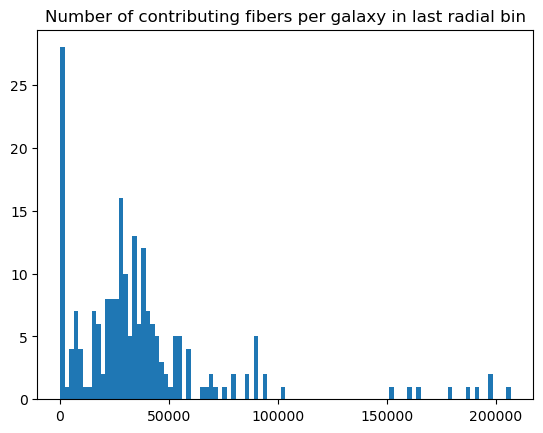

In [399]:
plt.hist(prod.nfib[:, -1], 100)
plt.title("Number of contributing fibers per galaxy in last radial bin")

In [4]:
cfg2 = replace(cfg, field="BOTH")          # or set field="BOTH" in run_config.py
stacks = run_stack(cfg2)                   # auto-loads both, cuts, stacks all 4 methods

Finite-spectrum cut (bin 5, > 100 px): kept 89 / 100 galaxies
Capping logMstar 11.37 -> 11.00, z=2.163
Capping logMstar 11.01 -> 11.00, z=2.296
Capping logMstar 11.34 -> 11.00, z=2.297
Capping logMstar 11.34 -> 11.00, z=2.297
Capping logMstar 11.04 -> 11.00, z=2.187
Capping logMstar 11.21 -> 11.00, z=2.471


# Measuring

In [5]:
flux_rf = stacks['stacks']["biweight"]['flux']   # (ngal, nrad, nwave) -- use your actual key
err_rf  = stacks['stacks']["biweight"]['err']
rest_wave = stacks["rest_wave"]

print(flux_rf.shape)
print(err_rf.shape)
print(rest_wave.shape)

(6, 6001)
(6, 6001)
(6001,)


In [6]:
N_gal = np.zeros_like(rest_wave, dtype=int)
gal_z = prod.catalog['z']

for z in gal_z:
    covered = (
        (rest_wave >= 3470/(1+z)) &
        (rest_wave <= 5540/(1+z)))
    N_gal[covered] += 1

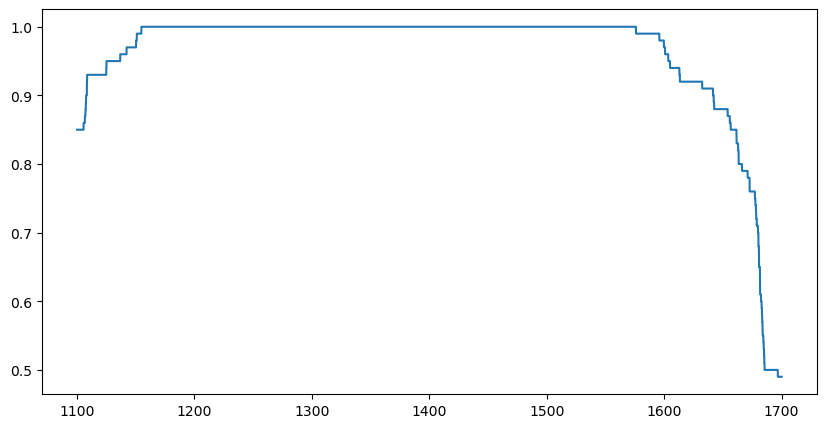

In [7]:
plt.figure(figsize=(10, 5))
plt.plot(rest_wave, N_gal/max(N_gal))

[ 90978 197975 188017  80368  94641  86865  80560  86863  76422 152868]
[22155 41594 39949 26269 29406 30469 48235 27358 38912 41092 37322 35164
 34471 26245 58407 27983 49315 25809     0     0 29167 39503 28818 45636
 15728 27853 28434 15046 18633 32023 22975 36863  3649  6538 54745 68847
 54108 20813 33547 69965 51758 35773 30192 17680  9503 14134 52626  8015
  6980  6538   645    26 15414     0    26   397  5182 24959 33859 18100
  5780 11179     0     0     0     0     0 17591 16297 43728     0 52250
 32558 32606  8307 14625  9983     0     0  9790 20431 39000 22974 52263
 43204 37017 35057 35059 39249 39094]


/tmp/ipykernel_10165/3761019730.py:10: RuntimeWarning: Mean of empty slice
  plt.plot(np.nanmean(prod.err[high_fiber_count][:, -1, :], axis=0), label='high fiber mean')
/tmp/ipykernel_10165/3761019730.py:11: RuntimeWarning: Mean of empty slice
  plt.plot(np.nanmean(prod.err[low_fiber_count][:, -1, :], axis=0), label='all fiber - high fiber mean')
/tmp/ipykernel_10165/3761019730.py:16: RuntimeWarning: All-NaN slice encountered
  plt.plot(np.nanmedian(prod.err[high_fiber_count][:, -1, :], axis=0), label='high fiber median')
/tmp/ipykernel_10165/3761019730.py:17: RuntimeWarning: All-NaN slice encountered
  plt.plot(np.nanmedian(prod.err[low_fiber_count][:, -1, :], axis=0), label='all fiber - high fiber median')


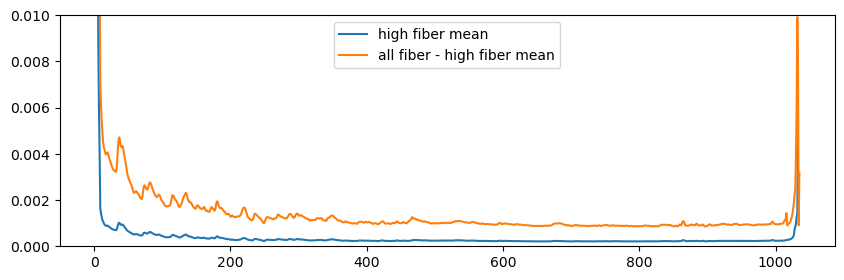

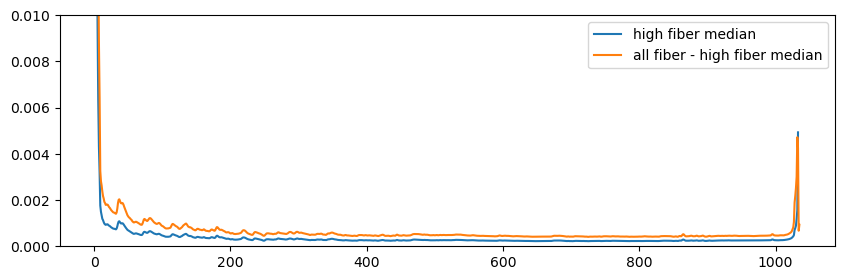

In [8]:
percentile = 90

high_fiber_count = prod.nfib[:, -1] > np.percentile(prod.nfib[:, -1], percentile)
print(prod.nfib[:, -1][high_fiber_count])

low_fiber_count = prod.nfib[:, -1] < np.percentile(prod.nfib[:, -1], percentile)
print(prod.nfib[:, -1][low_fiber_count])

plt.figure(figsize=(10, 3))
plt.plot(np.nanmean(prod.err[high_fiber_count][:, -1, :], axis=0), label='high fiber mean')
plt.plot(np.nanmean(prod.err[low_fiber_count][:, -1, :], axis=0), label='all fiber - high fiber mean')
plt.ylim(0, 0.01)
plt.legend()

plt.figure(figsize=(10, 3))
plt.plot(np.nanmedian(prod.err[high_fiber_count][:, -1, :], axis=0), label='high fiber median')
plt.plot(np.nanmedian(prod.err[low_fiber_count][:, -1, :], axis=0), label='all fiber - high fiber median')
plt.ylim(0, 0.01)
plt.legend()

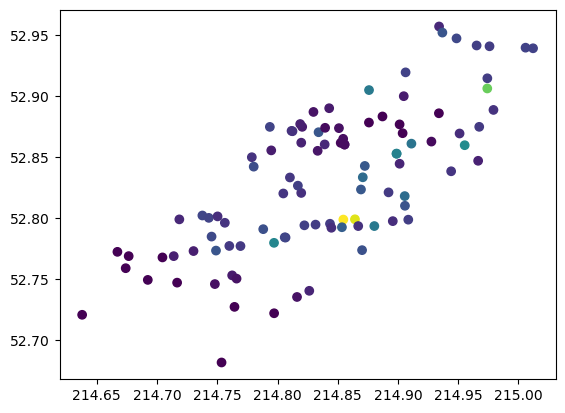

In [9]:
plt.scatter(prod.catalog['RA'], prod.catalog['DEC'], c=prod.nfib[:, -1])

89


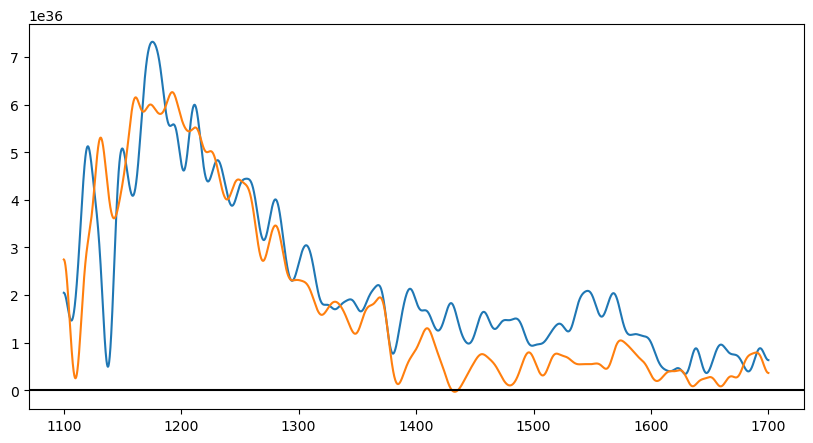

In [10]:
fiber_cuts = prod.nfib[:, -1] > 0
print(np.sum(fiber_cuts))

high_fiber_count_cut = high_fiber_count[fiber_cuts]
high_fiber_median_spec = np.nanmedian(stacks['cube_flux'][:, -1, :][high_fiber_count_cut], axis=0)

low_fiber_median_spec = np.nanmedian(stacks['cube_flux'][:, -1, :][~high_fiber_count_cut], axis=0)

plt.figure(figsize=(10, 5))
plt.plot(stacks["rest_wave"], gaussian_filter1d(high_fiber_median_spec, sigma=50))
plt.plot(stacks["rest_wave"], gaussian_filter1d(low_fiber_median_spec, sigma=50))
plt.axhline(0, c='k')

4.3567215500797854e+36 4.0615505720377643e+36


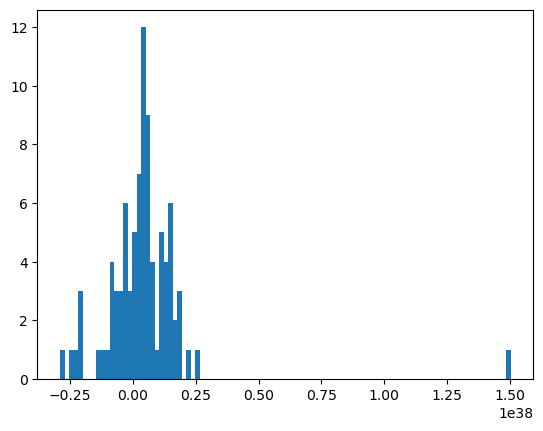

In [19]:
blue = np.nanmean(stacks['cube_flux'][:, -1, 0:1000], axis=1)
plt.hist(blue, 100)

print(np.nanmean(blue), np.nanmedian(blue))

In [ ]:
'''
I am debugging a stacking issue in large radial bins of a VIRUS-based CGM stack. The pipeline has two stages:

1. Stack fibers within each galaxy/radial bin to produce one spectrum per galaxy.
2. Stack the galaxy spectra to produce the final composite.

Originally, I thought the best approach was to stack fibers with inverse-variance weighting and then stack galaxies with a robust estimator (biweight). However, I am now questioning whether the problem is actually introduced at the fiber-stacking stage.

Key observations:

* The outer radial bins contain the most data (thousands of fibers and many galaxies), so this is not a low-number-statistics issue.
* Galaxy completeness is still high in the problematic blue region (~85% of galaxies contribute there).
* High-fiber galaxies alone reproduce essentially the same outer-bin spectrum, so the effect is not caused by mixing high- and low-fiber-count galaxies.
* Mean and median per-galaxy blue fluxes are very similar, suggesting the galaxy-level distribution is not strongly skewed.

Most importantly:

* If fibers are stacked with inverse-variance weighting, the final stacked spectrum shows a strong blue-end rise.
* If fibers are stacked with a biweight, that rise is greatly reduced.
* At the galaxy-stacking stage, both biweight and inverse-variance methods still show the rise, while the simple mean is much cleaner.

This suggests the issue may be injected before the galaxy stack is formed. One hypothesis is that inverse-variance weighting at the fiber level is systematically biasing galaxy spectra upward in the blue, perhaps because residual sky/background structure is correlated with the quoted variances. In that scenario, the galaxy stack can only propagate a bias that is already present in the individual galaxy spectra.

The main question is therefore: why would inverse-variance stacking of fibers produce a systematically elevated blue continuum compared to a biweight fiber stack, especially in the regime of extremely large fiber counts where statistical uncertainties become tiny and small systematics may dominate?
'''

In [ ]:
'''
Your hypothesis is right, and the cleanest way to see it is to start from what the disagreement itself tells you, before worrying about the mechanism.
The disagreement is the proof. For Gaussian noise with correct variances, inverse-variance and biweight estimate the same population mean — they differ only in efficiency, not in expectation. So a systematic offset between them, reproducible and growing with N, is by itself evidence that the assumption underlying inverse-variance — Gaussian scatter with correctly-quoted σ — is violated at the blue end. You don't have to guess that something is wrong with the errors; the inv_var−biweight difference spectrum being ~0 in the red and rising in the blue is a measurement of where the noise model breaks.
Why the bias is positive. Write the fiber stack as a weighted mean, fˉw=∑iwifi/∑iwi\bar f_w = \sum_i w_i f_i / \sum_i w_i
fˉ​w​=∑i​wi​fi​/∑i​wi​ with wi=1/σi2w_i = 1/\sigma_i^2
wi​=1/σi2​. Treating fibers as draws, its expectation is
E[fˉw]≈E[f]+Cov(w,f)E[w]=E[f]+Cov(1/σ2, f)E[1/σ2].E[\bar f_w] \approx E[f] + \frac{\mathrm{Cov}(w, f)}{E[w]} = E[f] + \frac{\mathrm{Cov}(1/\sigma^2,\, f)}{E[1/\sigma^2]}.E[fˉ​w​]≈E[f]+E[w]Cov(w,f)​=E[f]+E[1/σ2]Cov(1/σ2,f)​.
Inverse-variance is unbiased only when that covariance is zero — when a fiber's quoted precision is statistically independent of its flux. A blue rise means Cov(1/σ2,f)>0\mathrm{Cov}(1/\sigma^2, f) > 0
Cov(1/σ2,f)>0 at the blue end: the fibers with the *smallest quoted variance* tend to carry the *highest flux*. Biweight is insensitive to this because it never looks at σ\sigma
σ at all — it finds the robust center of the ff
f distribution and rejects the high values regardless of how confident their error bars claim to be.
So the question becomes: why do small-σ fibers carry excess blue flux? At the VIRUS blue end the formal variance is essentially photon + read noise, flux-calibrated. The contaminants that actually dominate there are not in that model and are positive-definite: scattered light from bright continuum sources, imperfect sky-subtraction residuals, faint undetected sources in the fiber, CCD background/bias structure, fiber-to-fiber flat/throughput errors. A fiber can look pristine to the noise model (small formal σ → large weight) while sitting on one of these positive floors. Inverse-variance trusts the formal σ, up-weights exactly those fibers, and propagates their positive offset. The contamination doesn't have to be "outliers" in the catastrophic sense — a coherent positive floor that the error model misses is enough.
**Why huge N makes it worse, not better.** This is the part that surprises people. The random term in fˉw\bar f_w
fˉ​w​ shrinks as 1/∑wi→01/\sqrt{\sum w_i} \to 0
1/∑wi​​→0, but the bias Cov(w,f)/E[w]\mathrm{Cov}(w,f)/E[w]
Cov(w,f)/E[w] is a property of the fiber *population*, independent of N. As you pile up thousands of fibers you drive the variance to zero and leave the bias fully exposed and rock-steady. More data sharpens the systematic into a high-significance feature rather than averaging it down. That is exactly your regime: the data-rich outer bins show the cleanest, strongest rise precisely because there's no longer any random scatter to hide it. A bias that *gets crisper* with N is the signature here; a statistical fluctuation would do the opposite.
This explains every box you've already ticked. Not low-N statistics — correct, it's a bias, and biases don't care about N (they're sharper at high N). Galaxy completeness ~85% — correct, it's a per-fiber systematic spread across the sample, not a few rogue galaxies. High-fiber galaxies reproduce it — those galaxies have the most blue fibers and the smallest formal errors, so they're the most exposed to the inv_var bias, not the least. Mean ≈ median per galaxy — correct and consistent: the bias is a coherent shift baked into each galaxy spectrum at the fiber stage, so it doesn't manifest as galaxy-to-galaxy skew; the galaxy-level distribution can look perfectly symmetric while every member is offset the same way. The galaxy stack can then only propagate a bias that already exists in its inputs, which is your conclusion.
One caution on the galaxy-stage pattern. "Biweight and inv_var show the rise, mean is cleaner" is a trap worth naming. If the bias were truly in the bulk of the galaxies, the mean would show it too — so the mean looking cleaner most likely means a population of negative blue residuals (sky over-subtraction in some galaxies) is partially cancelling the positive bias in the average, while biweight rejects those negatives and reports the biased-high center. That's two systematics cancelling by luck, not a correct measurement. Switching the galaxy combine to mean would be cancelling one wrong with another, and the cancellation won't hold across radius, redshift, or field. The fix belongs at the fiber stage where the cause is.
Confirming it concretely. A few cheap tests, in order of decisiveness:

Reduced-χ² vs wavelength. In a line-free blue window of an outer bin, compare the empirical fiber-to-fiber scatter to the median quoted σ. Expect χν2≈1\chi^2_\nu \approx 1
χν2​≈1 in the red and ≫1\gg 1
≫1 blueward — that's the error-model failure, localized in wavelength.
The covariance directly. Compute Cov(1/σ2,f)\mathrm{Cov}(1/\sigma^2, f)
Cov(1/σ2,f) per wavelength across the outer-bin fibers; it's literally the bias term, and it should turn positive exactly where the rise appears.
Top-weight fibers. Histogram the flux of the highest-weight (smallest-σ) decile of blue fibers against the full distribution; if they sit systematically above the biweight center, you've localized the offending fibers.

Fixes. Your own plan flags inv_var as "a faster alternative for the densely populated outer bins" — i.e. you adopted it for speed (fiber_combine_method = "inv_var" in run_config), and the outer bins are exactly where it bites. The clean fix is to fiber-combine with biweight (your stated default) or median, which you've already shown kills the rise. If you want to keep inv_var's speed, the principled patch is to make the errors honest: measure χν2(λ)\chi^2_\nu(\lambda)
χν2​(λ) and inflate σ by χν2\sqrt{\chi^2_\nu}
χν2​​, or add a systematic floor in quadrature, so the weights stop over-trusting the contaminated fibers (in the limit where the floor dominates, inv_var degrades gracefully toward unweighted). A sigma-clip-then-inv_var hybrid is a middle path. But biweight is the lower-risk choice and the math says it's doing the right thing.
Why this matters beyond cosmetics. Your centroid pipeline subtracts a sideband continuum (cont_bounds includes 1195–1210 Å, blueward of Lyα). A biased-high blue continuum biases that subtraction, which pushes the recovered centroid red and suppresses the blue-side flux in blue_red_side_ratio. Whether it reaches the rest-frame sidebands depends on redshift mixing — the observed blue end maps to rest ~990 Å at z≈2.5 but lands near Lyα itself for your lowest-z galaxies (Lyα enters at 3470 Å around z≈1.85) — so after stacking a redshift range the contamination smears across a band of rest wavelengths rather than sitting at one. It's worth checking explicitly whether that smeared band overlaps your continuum windows, because if it does, the fiber-stage choice could be feeding the inner-bin positive centroids you see in the headline figure. That would make this a science systematic, not just a continuum nuisance.
If it's useful I can write the χ²ᵥ(λ) and Cov(1/σ², f) diagnostics as a small function against combine_fibers — it would slot alongside the validation module and give you the confirmation plots directly. Want me to?
'''

In [5]:
flux_rf = stacks['cube_flux']   # (ngal, nrad, nwave) -- use your actual key
err_rf  = stacks['cube_err']
rest_wave = stacks["rest_wave"]

se = measure.bootstrap_stack_error(flux_rf, err_rf=err_rf, 
    nboot=1000, stack_method="biweight",
    robust=True, seed=1, verbose=True, return_draws=False)

  0%|          | 0/1000 [00:00<?, ?it/s]

In [8]:
lya_window_mask = ((rest_wave >= 1150) & (rest_wave <= 1300))

# your propagated/intrinsic stack error, the thing to compare against:
propagated = np.sqrt(np.nanmean(err_rf[:, :, lya_window_mask]**2, axis=0)) / np.sqrt(flux_rf[:, :, lya_window_mask].shape[0])
ratio = se["stack_err"][:, lya_window_mask] / propagated     # (nrad, nwave); >1 => bootstrap finds more scatter

print("median boot/propagated per bin: \n", np.nanmedian(ratio, axis=1))

median boot/propagated per bin: 
 [0.82569005 0.82172242 0.77436872 0.48168158 0.90062573 0.34907072]


In [7]:
b = measure.bootstrap_measurements(flux_rf, err_rf, rest_wave,
    nboot=1000,
    cont_bounds=((1185, 1200), (1230, 1245)),
    stack_method="biweight",
    cont_method="poly", 
    cont_order=1,
    compute_side_ratio=True,
    clip_negative_sides=False,
    seed=1, 
    verbose=True)

  0%|          | 0/1000 [00:00<?, ?it/s]

# Auto/Cross-Correlation Tests

In [6]:
import numpy as np
from scipy.optimize import curve_fit
from scipy.special import gamma as Gamma

def fit_wp_powerlaw(rp, wp, wp_err=None, gamma_guess=1.8, r0_guess=5.0):
    """
    Fit wp(rp) = rp * (rp/r0)^-gamma * B(gamma), the standard projected
    correlation function power-law form (B is the Gamma-function prefactor
    relating wp to xi(r) = (r/r0)^-gamma).

    rp : projected separations [h^-1 Mpc]
    wp : measured w_p(rp) [h^-1 Mpc]
    wp_err : optional 1-sigma errors on wp, for weighted fit

    Returns dict with r0, gamma (+ 1-sigma uncertainties) and a callable
    xi_of_r(r) giving the recovered 3D correlation function.
    """
    def model(rp, r0, gamma):
        B = np.sqrt(np.pi) * Gamma((gamma - 1) / 2) / Gamma(gamma / 2)
        return rp * (rp / r0) ** (-gamma) * B

    sigma = wp_err if wp_err is not None else None
    popt, pcov = curve_fit(model, rp, wp, p0=[r0_guess, gamma_guess],
                           sigma=sigma, absolute_sigma=sigma is not None)
    r0, gamma = popt
    r0_err, gamma_err = np.sqrt(np.diag(pcov))

    def xi_of_r(r):
        return (np.asarray(r, dtype=float) / r0) ** (-gamma)

    return {"r0": r0, "r0_err": r0_err, "gamma": gamma, "gamma_err": gamma_err,
            "model_wp": model, "xi_of_r": xi_of_r}


def overdensity_table(fit, r_list_Mpc):
    """
    Given a fit_wp_powerlaw result, print xi(r) = 1+delta at a list of
    3D separations (in h^-1 Mpc), normalized to the SHORTEST radius given
    so you get the "X, 0.5X, 0.2X..." style readout.
    """
    r_list_Mpc = np.asarray(r_list_Mpc, dtype=float)
    xi = fit["xi_of_r"](r_list_Mpc)
    xi_norm = xi / xi[0]
    print(f"r0 = {fit['r0']:.2f} +/- {fit['r0_err']:.2f} h^-1 Mpc, "
          f"gamma = {fit['gamma']:.2f} +/- {fit['gamma_err']:.2f}\n")
    for r, x, xn in zip(r_list_Mpc, xi, xi_norm):
        print(f"  r = {r*1000:6.0f} kpc  ->  xi(r) = {x:7.4f}   "
              f"(relative to first point: {xn:.4f}x)")
    return xi, xi_norm

In [9]:
# Approximate data points read from the figure (rp in h^-1 Mpc, wp in h^-1 Mpc)
rp  = np.array([0.4, 0.6, 0.9, 1.3, 2.0, 3.0, 4.5, 7.0, 10.0, 15.0])
wp  = np.array([100, 70,  50,  35,  40,  25,  20,  11,   8,    5.5])
wp_err = np.array([20, 12, 10, 8, 7, 4, 3, 2, 1.5, 1.2])

fit = fit_wp_powerlaw(rp, wp, wp_err)

# Your requested style: overdensity at 100 kpc, 500 kpc, 1 Mpc, etc.
r_targets_Mpc = np.array([0.05, 0.1, 0.2, 0.5, 1.0, 2.0])   # h^-1 Mpc
xi, xi_norm = overdensity_table(fit, r_targets_Mpc)

r0 = 4.33 +/- 0.15 h^-1 Mpc, gamma = 1.76 +/- 0.05

  r =     50 kpc  ->  xi(r) = 2588.4744   (relative to first point: 1.0000x)
  r =    100 kpc  ->  xi(r) = 763.5302   (relative to first point: 0.2950x)
  r =    200 kpc  ->  xi(r) = 225.2209   (relative to first point: 0.0870x)
  r =    500 kpc  ->  xi(r) = 44.8435   (relative to first point: 0.0173x)
  r =   1000 kpc  ->  xi(r) = 13.2276   (relative to first point: 0.0051x)
  r =   2000 kpc  ->  xi(r) =  3.9018   (relative to first point: 0.0015x)


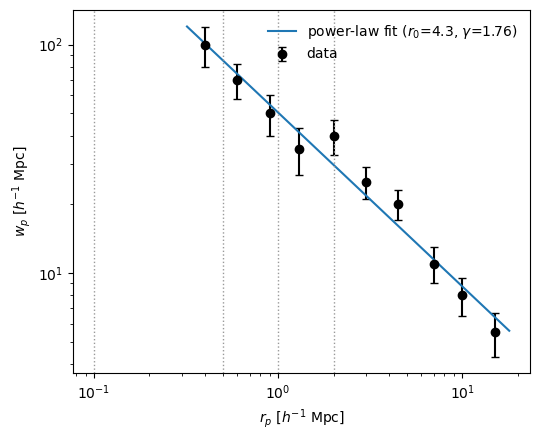

In [3]:
import matplotlib.pyplot as plt

rp_fine = np.geomspace(rp.min()*0.8, rp.max()*1.2, 200)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.errorbar(rp, wp, yerr=wp_err, fmt='o', color='k', capsize=3, label='data')
ax.plot(rp_fine, fit["model_wp"](rp_fine, fit["r0"], fit["gamma"]),
       color='tab:blue', label=fr"power-law fit ($r_0$={fit['r0']:.1f}, $\gamma$={fit['gamma']:.2f})")
for rt in r_targets_Mpc:
    ax.axvline(rt, color='0.6', ls=':', lw=1)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r"$r_p$ [$h^{-1}$ Mpc]")
ax.set_ylabel(r"$w_p$ [$h^{-1}$ Mpc]")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In [11]:
import numpy as np

def xi_powerlaw(r_Mpc, r0=7.0, gamma=1.8):
    """
    3D correlation function xi(r) = (r/r0)^-gamma.
    r_Mpc : separation(s) in the SAME units as r0 (e.g. h^-1 cMpc)
    r0    : correlation length
    gamma : power-law slope
    Returns xi(r), same shape as r_Mpc.
    """
    r_Mpc = np.asarray(r_Mpc, dtype=float)
    return (r_Mpc / r0) ** (-gamma)


def fractional_curve(r_Mpc, r0=7.0, gamma=1.8, r_ref=None):
    """
    Evaluate xi(r) and normalize it relative to xi at a reference radius
    (default: the smallest r in r_Mpc), giving the "X, 0.5X, 0.2X..." style
    fractional curve.

    r_ref : reference separation for normalization (same units as r0).
            If None, uses r_Mpc.min().
    Returns (xi, xi_frac).
    """
    r_Mpc = np.asarray(r_Mpc, dtype=float)
    xi = xi_powerlaw(r_Mpc, r0=r0, gamma=gamma)
    ref = r_Mpc.min() if r_ref is None else r_ref
    xi_ref = xi_powerlaw(ref, r0=r0, gamma=gamma)
    return xi, xi / xi_ref

In [18]:
r0 = 7.0      # h^-1 cMpc, as you've fixed it
gamma = 1.8   # canonical slope; swap in your fit value if you have one

r_targets_Mpc = np.array([0.1, 0.5, 1.0, 2.0, 5.0])   # h^-1 Mpc

xi, xi_frac = fractional_curve(r_targets_Mpc, r0=r0, gamma=gamma)

for r, x, f in zip(r_targets_Mpc, xi, xi_frac):
    print(f"r = {r*1000:6.0f} kpc   xi(r) = {x:8.2f}   ({f:.5f}x of r={r_targets_Mpc[0]*1000:.0f} kpc value)")

r =    100 kpc   xi(r) =  2094.96   (1.00000x of r=100 kpc value)
r =    500 kpc   xi(r) =   115.62   (0.05519x of r=100 kpc value)
r =   1000 kpc   xi(r) =    33.20   (0.01585x of r=100 kpc value)
r =   2000 kpc   xi(r) =     9.54   (0.00455x of r=100 kpc value)
r =   5000 kpc   xi(r) =     1.83   (0.00087x of r=100 kpc value)


# COSMOS-Web Catalog Spec-z

https://ui.adsabs.harvard.edu/abs/2026ApJS..282....6K/abstract

In [360]:
import numpy as np
from astropy.table import Table, join
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# 1. LOAD  (with a Git-LFS stub guard — the #1 gotcha with this repo)
# ----------------------------------------------------------------------
def load_specz(path):
    # LFS pointer files are ~130 bytes of text, not FITS. Catch that early.
    with open(path, "rb") as f:
        head = f.read(64)
    if head.startswith(b"version https://git-lfs"):
        raise IOError(f"{path} is a Git-LFS pointer, not the real FITS. "
                      "Download from the Releases page or run `git lfs pull`.")
    tbl = Table.read(path)
    print(f"Loaded {len(tbl):,} rows")
    print("Columns:", list(tbl.colnames))
    return tbl

# ----------------------------------------------------------------------
# 2. AUTO-DETECT the columns we care about (edit the map if it guesses wrong)
# ----------------------------------------------------------------------
def auto_columns(tbl):
    def pick(cands):
        low = {c.lower(): c for c in tbl.colnames}
        for c in cands:
            if c in low: return low[c]
        return None
    cols = dict(
        id   = pick(["Id_specz", "source_id", "objid", "cosmos2020_id"]),
        ra   = pick(["ra_original", "alpha_j2000", "ra_deg"]),
        dec  = pick(["dec_original", "delta_j2000", "dec_deg"]),
        z    = pick(["zspec", "z_spec", "redshift", "z", "specz"]),
        flag = pick(["q", "qf", "quality_flag", "qflag", "flag", "zquality"]),
    )
    print("Detected mapping:", cols)
    missing = [k for k, v in cols.items() if v is None]
    if missing:
        print(f"  !! could not auto-find: {missing} — set them by hand below")
    return cols

# ----------------------------------------------------------------------
# 3. SELECT the science sample
#    quality system: base flag = flag % 10 ; broad-line (BL-AGN) = flag >= 10
#    base flags: 4=97%, 3=95%, 9=single-line 85%, 2=80%, 1=50%, 0=none
# ----------------------------------------------------------------------
VALID_BASE = {0, 1, 2, 3, 4, 9}        # everything else (-99,-2,-1,5,6) is junk
def decode_flags(flag):
    """Return (base, is_bl, is_valid) from the raw +10-broad-line scheme."""
    flag  = np.asarray(flag).astype(int)
    is_bl = flag >= 10
    base  = np.where(is_bl, flag - 10, flag)
    is_valid = np.isin(base, list(VALID_BASE))   # filters sentinels & 5/6
    return base, is_bl, is_valid

def select_sample(tbl, cols, zlo=1.9, zhi=3.5,
                  secure={3, 4}, include_moderate=False, drop_bl=True):
    z = np.asarray(tbl[cols["z"]], float)
    base, is_bl, is_valid = decode_flags(tbl[cols["flag"]])

    good = set(secure) | ({2, 9} if include_moderate else set())
    keep = (np.isin(base, list(good)) & is_valid
            & (z >= zlo) & (z <= zhi) & np.isfinite(z)
            & (~is_bl if drop_bl else True))

    print(f"z in [{zlo},{zhi}], base flags {sorted(good)}"
          f"{', no BL-AGN' if drop_bl else ''}: {keep.sum():,} galaxies")
    print(f"  secure BL-AGN in window (excluded): "
          f"{(np.isin(base,list(secure)) & is_valid & is_bl & (z>=zlo)&(z<=zhi)).sum():,}")
    out = tbl[keep].copy()
    out["_zspec"] = z[keep]; out["_base_flag"] = base[keep]
    return out, keep

# ----------------------------------------------------------------------
# 4. MERGE the SED fitting (mass / SFR / dust) — the subset with COSMOS2020 match
# ----------------------------------------------------------------------
def merge_sed(specz, sed_path, key="Id_specz"):
    sed = Table.read(sed_path)
    if key in specz.colnames and key in sed.colnames:
        merged = join(specz, sed, keys=key, join_type="left")
        print(f"  joined on '{key}': {len(merged):,} rows")
        return merged
    raise KeyError(f"'{key}' not in both tables")


def vdfi_fiber_positions(base_path):
    """Pull all good fiber RA/DEC for a field straight from all_info.fits,
    matching extract.load_vdfi_field's reshape (nexp, nfib) -> flat (Nfiber,)."""
    with fits.open(f"{base_path}/all_info.fits") as info:
        RA  = info[1].data * 1.0
        DEC = info[2].data * 1.0
    RA  = RA.reshape(RA.shape[0],  RA.shape[1]  * RA.shape[2])     # (nexp, nfib)
    DEC = DEC.reshape(DEC.shape[0], DEC.shape[1] * DEC.shape[2])
    ra  = RA.ravel(); dec = DEC.ravel()
    good = np.isfinite(ra) & np.isfinite(dec)
    print(f"  {good.sum():,} good fibers of {ra.size:,} "
          f"(RA {np.nanmin(ra[good]):.3f}–{np.nanmax(ra[good]):.3f}, "
          f"DEC {np.nanmin(dec[good]):.3f}–{np.nanmax(dec[good]):.3f})")
    return ra[good], dec[good]

def in_vdfi_footprint(cat_ra, cat_dec, fib_ra, fib_dec,
                      max_sep_arcsec=60.0, need_frac=None, n_check=8):
    """
    True for catalog galaxies that have VDFI fiber coverage.

    A galaxy is 'covered' if the nearest fiber is within max_sep_arcsec. Set
    max_sep_arcsec to the OUTER radius you intend to stack to (your background
    annulus is 57–63", so 60" means 'a fiber exists at the galaxy position';
    raise it if you need full annulus coverage, lower it for core-only).

    need_frac (optional, 0–1): require that this fraction of n_check points on a
    ring at max_sep_arcsec also have a fiber within ~one fiber spacing — i.e.
    demand the galaxy is genuinely surrounded, not on a ragged edge or in an
    internal gap. None skips this (faster, edge-permissive).
    """
    from astropy.coordinates import SkyCoord
    import astropy.units as u

    fib = SkyCoord(fib_ra * u.deg, fib_dec * u.deg)
    gal = SkyCoord(cat_ra * u.deg, cat_dec * u.deg)

    idx, d2d, _ = gal.match_to_catalog_sky(fib)          # nearest fiber per galaxy
    covered = d2d.arcsec <= max_sep_arcsec

    if need_frac is not None:
        ang = np.linspace(0, 2*np.pi, n_check, endpoint=False)
        cosd = np.cos(np.deg2rad(cat_dec))
        ok_ring = np.zeros(cat_ra.size)
        for a in ang:                                     # ring points around each galaxy
            rra  = cat_ra  + (max_sep_arcsec/3600.)*np.cos(a)/cosd
            rdec = cat_dec + (max_sep_arcsec/3600.)*np.sin(a)
            _, dr, _ = SkyCoord(rra*u.deg, rdec*u.deg).match_to_catalog_sky(fib)
            ok_ring += (dr.arcsec <= 15.0)                # ~one fiber spacing
        covered &= (ok_ring/n_check >= need_frac)
    return covered, d2d.arcsec


# ---- safe column getter (handles masked join columns -> NaN) ----
def _col(tbl, name):
    if name not in tbl.colnames:
        return None
    c = np.ma.asarray(tbl[name], dtype=float)
    return np.asarray(np.ma.filled(c, np.nan), float)

def _abmag(flux_mjy):
    """CIGALE fluxes are mJy by default -> AB mag (zp 16.40). Non-detections->NaN."""
    f = np.asarray(flux_mjy, float)
    with np.errstate(invalid="ignore", divide="ignore"):
        m = -2.5 * np.log10(f) + 16.40
    m[~np.isfinite(m)] = np.nan
    return m

def sample_property_panels(tbl):
    """Build (title, values, xlabel, log_x?) for each diagnostic that exists."""
    M    = _col(tbl, "bayes.stellar.m_star")          # Msun, linear
    SFR  = _col(tbl, "bayes.sfh.sfr")                 # Msun/yr, linear
    ebv  = _col(tbl, "bayes.attenuation.E_BV_lines")  # nebular E(B-V)
    beta = _col(tbl, "bayes.param.beta_calz94")       # UV slope
    ewly = _col(tbl, "bayes.param.EW(LyA)")           # MODEL Lya EW (not measured!)
    z    = _col(tbl, "_zspec")
    fi   = _col(tbl, "subaru.suprime.i")              # observed fluxes (mJy)
    fKs  = _col(tbl, "paranal.vircam.Ks")
    f814 = _col(tbl, "hst.acs.wfc.F814W")

    logM   = np.log10(M)   if M   is not None else None
    logSFR = np.log10(SFR) if SFR is not None else None
    logsSFR = (np.log10(SFR) - np.log10(M)) if (M is not None and SFR is not None) else None
    AV     = ebv * 4.05 if ebv is not None else None  # Calzetti R_V

    panels = [
        ("Stellar mass",   logM,             r"$\log\,M_*\ [M_\odot]$"),
        ("SFR",            logSFR,            r"$\log\,\mathrm{SFR}\ [M_\odot/\mathrm{yr}]$"),
        ("sSFR",           logsSFR,           r"$\log\,\mathrm{sSFR}\ [\mathrm{yr}^{-1}]$"),
        ("Dust (nebular)", AV,                r"$A_V\ \ (=E(B-V)_{\rm lines}\times4.05)$"),
        ("UV slope",       beta,              r"$\beta_{\rm calz94}$"),
        ("i-band (obs)",   _abmag(fi)  if fi  is not None else None, r"$i_{\rm AB}$"),
        ("Ks-band (obs)",  _abmag(fKs) if fKs is not None else None, r"$Ks_{\rm AB}$"),
        ("F814W (obs)",    _abmag(f814) if f814 is not None else None, r"$F814W_{\rm AB}$"),
        ("Redshift",       z,                 r"$z_{\rm spec}$"),
        ("Model EW(Lya)*", ewly,              r"$EW_{\rm Ly\alpha}$ (SED, not measured)"),
    ]
    return [p for p in panels if p[1] is not None]

def plot_sample_properties(tbl, compare=None,
                           labels=("secure (3–4)", "comparison"), bins=35):
    panels  = sample_property_panels(tbl)
    cpanels = sample_property_panels(compare) if compare is not None else None
    n = len(panels); ncol = 5; nrow = int(np.ceil(n/ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.0*ncol, 2.7*nrow))
    axes = np.atleast_1d(axes).ravel()

    for ax, (title, vals, xlab) in zip(axes, panels):
        v = vals[np.isfinite(vals)]
        if v.size == 0:
            ax.text(0.5, 0.5, "no data", ha="center"); ax.set_title(title); continue
        rng = np.nanpercentile(v, [1, 99])                  # robust range
        edges = np.linspace(rng[0], rng[1], bins+1)
        ax.hist(v, bins=edges, color="#4daf4a", alpha=0.85,
                label=f"{labels[0]} (N={v.size:,})", density=True)
        if cpanels is not None:
            cv = dict((t, x) for t, x, _ in cpanels).get(title)
            if cv is not None:
                cv = cv[np.isfinite(cv)]
                ax.hist(cv, bins=edges, histtype="step", color="firebrick",
                        lw=1.6, label=f"{labels[1]} (N={cv.size:,})", density=True)
        ax.axvline(np.nanmedian(v), color="k", ls="--", lw=0.8)
        ax.set_title(title, fontsize=10); ax.set_xlabel(xlab, fontsize=9)
        ax.set_yticks([]); ax.legend(fontsize=6.5, framealpha=0.85)
        # magnitudes read brighter -> fainter left to right
        if "AB" in xlab: ax.invert_xaxis()

    for ax in axes[n:]:
        ax.set_visible(False)
    plt.tight_layout(); plt.show()

In [361]:
tbl_specz   = load_specz("specz_compilation_COSMOS_DR1.1_unique.fits")
cols_specz  = auto_columns(tbl_specz)

tbl_cigale   = load_specz("cigale_results_specz_compilation_DR1.1.fits")
cols_cigale  = auto_columns(tbl_cigale)

# if auto_columns missed one, just set it: cols["flag"] = "Q_flag"
sample, is_bl = select_sample(tbl_specz, cols_specz, zlo=1.9, zhi=3.5,
                              secure={3, 4}, include_moderate=False)

# attach dust/mass/SFR for the type-stratified medians:
sample = merge_sed(sample, "cigale_results_specz_compilation_DR1.1.fits")

Loaded 261,975 rows
Columns: ['Id_specz', 'Id_original', 'ra_original', 'dec_original', 'ra_corrected', 'dec_corrected', 'Priority', 'specz', 'flag', 'Confidence_level', 'survey', 'compilation_year', 'public_or_private', 'Id_COS20_Classic', 'ra_COS20_Classic', 'dec_COS20_Classic', 'Id_COS20_Farmer', 'ra_COS20_Farmer', 'dec_COS20_Farmer', 'Id_COSMOS25', 'ra_COSMOS25', 'dec_COSMOS25', 'Id_COSMOS15', 'ra_COSMOS15', 'dec_COSMOS15', 'Id_COSMOS09', 'ra_COSMOS09', 'dec_COSMOS09', 'photoz', 'photoz_type', 'GroupID', 'GroupSize']
Detected mapping: {'id': None, 'ra': 'ra_original', 'dec': 'dec_original', 'z': 'specz', 'flag': 'flag'}
  !! could not auto-find: ['id'] — set them by hand below
Loaded 111,269 rows
Columns: ['ID_COS20_Classic', 'Id_specz', 'specz', 'bayes.attenuation.E_BV_lines', 'bayes.attenuation.E_BV_lines_err', 'bayes.nebular.logU', 'bayes.nebular.logU_err', 'bayes.nebular.zgas', 'bayes.nebular.zgas_err', 'bayes.param.EW(Halpha)', 'bayes.param.EW(Halpha)_err', 'bayes.param.EW(Hbe

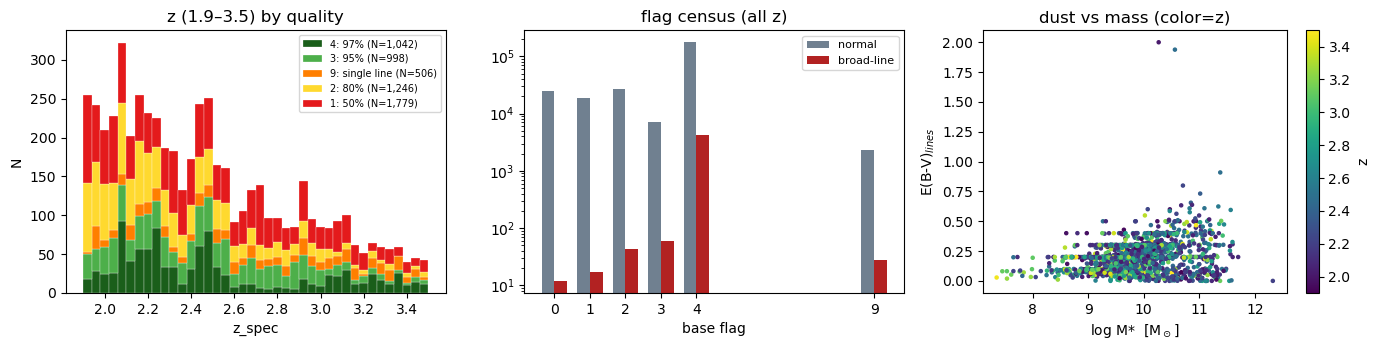

In [362]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))

# (a) z histogram in the HETDEX window, STACKED by base quality (galaxies only)
zfull = np.asarray(tbl_specz[cols_specz["z"]], float)
base, is_bl, is_valid = decode_flags(tbl_specz[cols_specz["flag"]])
win = (zfull >= 1.9) & (zfull <= 3.5) & np.isfinite(zfull) & is_valid & ~is_bl

order  = [4, 3, 9, 2, 1, 0]
labels = {4:"4: 97%", 3:"3: 95%", 9:"9: single line", 2:"2: 80%",
          1:"1: 50%", 0:"0: none"}
colors = {4:"#1a5e1a", 3:"#4daf4a", 9:"#ff7f00", 2:"#ffd92f",
          1:"#e41a1c", 0:"#999999"}
present = [f for f in order if np.any(win & (base == f))]
ax[0].hist([zfull[win & (base == f)] for f in present],
           bins=np.linspace(1.9, 3.5, 41), stacked=True,
           color=[colors[f] for f in present],
           label=[f"{labels[f]} (N={(win&(base==f)).sum():,})" for f in present],
           edgecolor="white", linewidth=0.2)
ax[0].set_xlabel("z_spec"); ax[0].set_ylabel("N")
ax[0].set_title("z (1.9–3.5) by quality"); ax[0].legend(fontsize=7)

# (b) full flag census: normal vs broad-line, valid bases only
ax[1].bar([f-0.18 for f in order],
          [(is_valid & ~is_bl & (base==f)).sum() for f in order],
          width=0.36, color="slategray", label="normal")
ax[1].bar([f+0.18 for f in order],
          [(is_valid &  is_bl & (base==f)).sum() for f in order],
          width=0.36, color="firebrick", label="broad-line")
ax[1].set_xticks(order); ax[1].set_xlabel("base flag")
ax[1].set_yscale("log"); ax[1].set_title("flag census (all z)"); ax[1].legend(fontsize=8)

# (c) representativeness: dust vs mass.  Real CIGALE columns from your dump:
mcol = "bayes.stellar.m_star"            # stellar mass (linear, Msun)
acol = "bayes.attenuation.E_BV_lines"    # nebular E(B-V) -> this is your dust axis
if mcol in sample.colnames and acol in sample.colnames:
    logM = np.log10(np.asarray(sample[mcol], float))
    ebv  = np.asarray(sample[acol], float)
    ok   = np.isfinite(logM) & np.isfinite(ebv)
    sc = ax[2].scatter(logM[ok], ebv[ok], s=5, c=sample["_zspec"][ok], cmap="viridis")
    ax[2].set_xlabel("log M*  [M$_\\odot$]"); ax[2].set_ylabel("E(B-V)$_{lines}$")
    ax[2].set_title("dust vs mass (color=z)")
    plt.colorbar(sc, ax=ax[2], label="z")
else:
    ax[2].text(0.5, 0.5, f"missing {mcol} / {acol}", ha="center")
plt.tight_layout(); plt.show()

In [363]:
# COSMOS VDFI fibers (EGS is a separate base_path; this compilation is COSMOS-only)
fib_ra, fib_dec = vdfi_fiber_positions("../../../../HETDEX-Work/vdfi/cosmos")

cra = np.asarray(sample[cols_specz["ra"]],  float)
cdec = np.asarray(sample[cols_specz["dec"]], float)

covered, nearest = in_vdfi_footprint(cra, cdec, fib_ra, fib_dec,
                                     max_sep_arcsec=60.0, need_frac=None)
print(f"\nsecure z=2 galaxies inside VDFI footprint: {covered.sum():,} "
      f"of {covered.size:,}")

sample_vdfi = sample[covered].copy()

  4,612,608 good fibers of 4,612,608 (RA 149.881–150.402, DEC 2.075–2.508)

secure z=2 galaxies inside VDFI footprint: 1,154 of 2,040


In [364]:
# if auto_columns missed one, just set it: cols["flag"] = "Q_flag"
sample2, is_bl = select_sample(tbl_specz, cols_specz, zlo=1.9, zhi=3.5,
                              secure={2, 3, 4}, include_moderate=False)

# attach dust/mass/SFR for the type-stratified medians:
sample2 = merge_sed(sample2, "cigale_results_specz_compilation_DR1.1.fits")

# COSMOS VDFI fibers (EGS is a separate base_path; this compilation is COSMOS-only)
fib_ra, fib_dec = vdfi_fiber_positions("../../../../HETDEX-Work/vdfi/cosmos")

cra = np.asarray(sample2[cols_specz["ra"]],  float)
cdec = np.asarray(sample2[cols_specz["dec"]], float)

covered, nearest = in_vdfi_footprint(cra, cdec, fib_ra, fib_dec,
                                     max_sep_arcsec=60.0, need_frac=None)
print(f"\nsecure z=2 galaxies inside VDFI footprint: {covered.sum():,} "
      f"of {covered.size:,}")

sample_vdfi2 = sample2[covered].copy()

z in [1.9,3.5], base flags [2, 3, 4], no BL-AGN: 3,286 galaxies
  secure BL-AGN in window (excluded): 1,746
  joined on 'Id_specz': 3,286 rows
  4,612,608 good fibers of 4,612,608 (RA 149.881–150.402, DEC 2.075–2.508)

secure z=2 galaxies inside VDFI footprint: 1,881 of 3,286


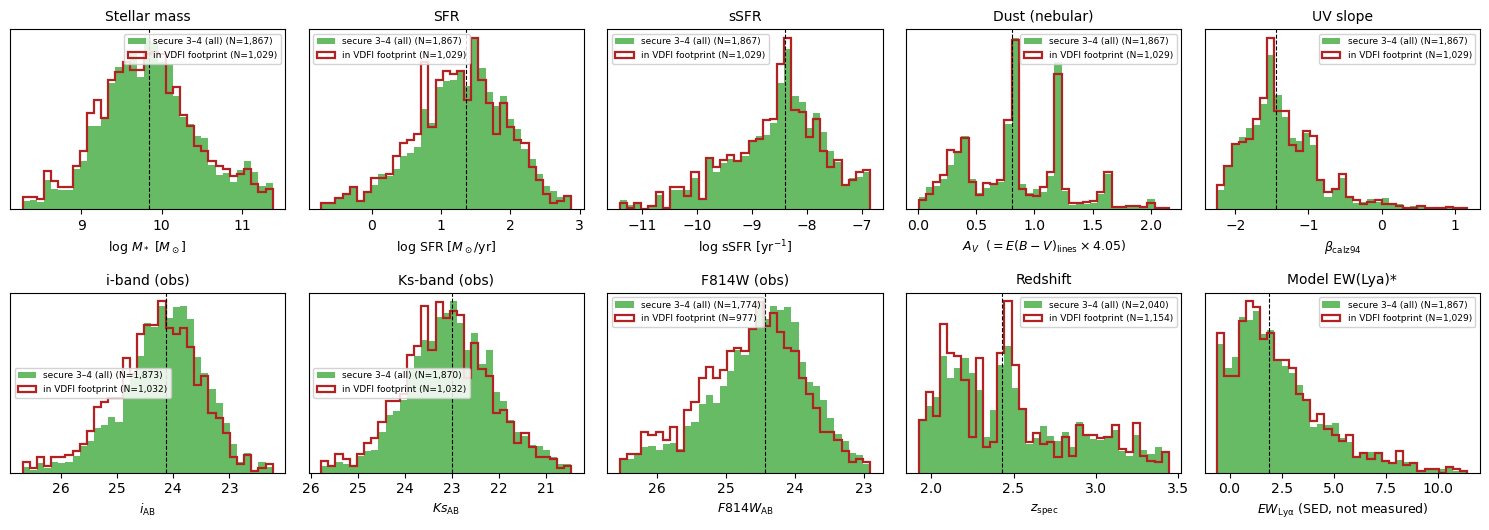

In [365]:
# sample        = secure flags 3–4 (2,040)
# sample_vdfi   = the covered subset inside VDFI footprint (1,154)
plot_sample_properties(sample, compare=sample_vdfi,
                       labels=("secure 3–4 (all)", "in VDFI footprint"))

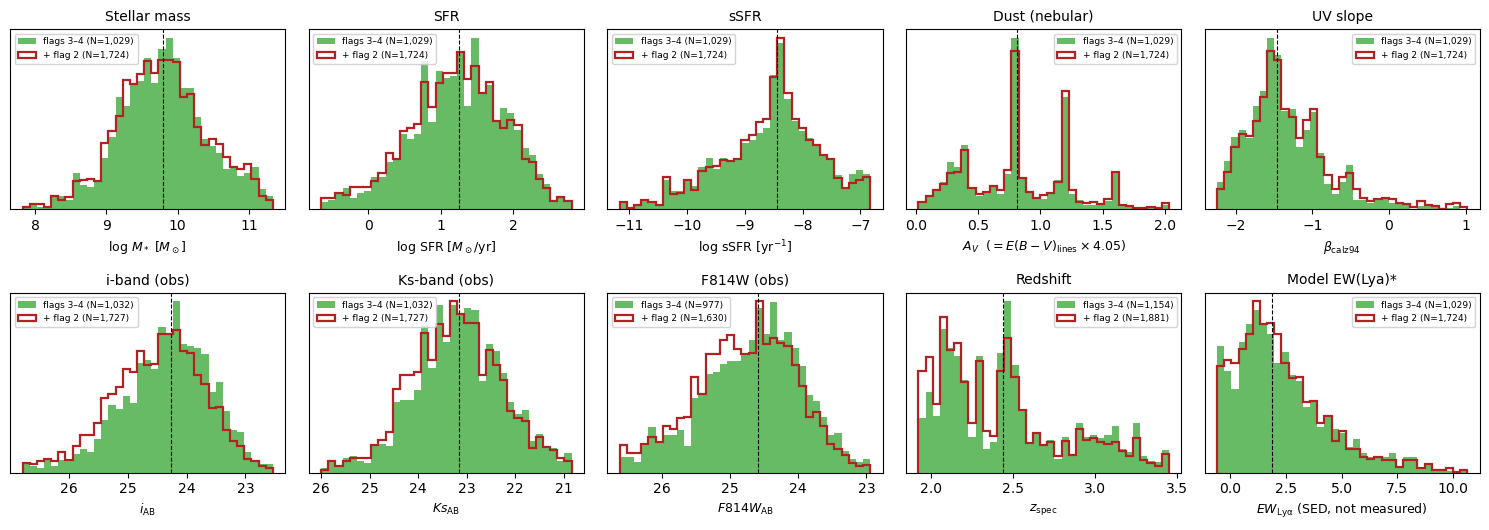

In [366]:
# does adding flag 2 shift the population? (purity-vs-bias check)
plot_sample_properties(sample_vdfi, compare=sample_vdfi2,
                       labels=("flags 3–4", "+ flag 2"))

# COSMOS-Web Photometric

https://ui.adsabs.harvard.edu/abs/2025A%26A...704A.339S/abstract

In [367]:
path = "COSMOSWeb_mastercatalog_v1.1_cigale.fits"   # add .fits if not already

# 1. Peek at structure WITHOUT loading the whole thing into memory
with fits.open(path, memmap=True) as hdul:
    hdul.info()                                  # which HDU holds the table
    print("\nN columns:", len(hdul[1].columns))
    print("N rows:", hdul[1].header.get("NAXIS2"))
    print(hdul[1].columns.names)

Filename: COSMOSWeb_mastercatalog_v1.1_cigale.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  CIGALE        1 BinTableHDU    122   784016R x 56C   [D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D]   

N columns: 56
N rows: 784016
['age_form', 'age_form_err', 'sfr_mass_vector_dir', 'sfr_mass_vector_dir_err', 'sfr_mass_vector_norm', 'sfr_mass_vector_norm_err', 'sfh_sfr_bin1', 'sfh_sfr_bin1_err', 'sfh_sfr_bin2', 'sfh_sfr_bin2_err', 'sfh_sfr_bin3', 'sfh_sfr_bin3_err', 'sfh_sfr_bin4', 'sfh_sfr_bin4_err', 'sfh_sfr_bin5', 'sfh_sfr_bin5_err', 'sfh_sfr_bin6', 'sfh_sfr_bin6_err', 'sfh_sfr_bin7', 'sfh_sfr_bin7_err', 'sfh_sfr_bin8', 'sfh_sfr_bin8_err', 'sfh_sfr_bin9', 'sfh_sfr_bin9_err', 'sfh_time_bin1', 'sfh_time_bin1_err', 'sfh_time_bin2', 'sfh_time_bin2_err', 'sfh_time_bin3', 'sfh_time_bin3_err', 'sfh_ti

In [368]:
path = "COSMOSWeb_mastercatalog_v1.1_lephare.fits"   # add .fits if not already

# 1. Peek at structure WITHOUT loading the whole thing into memory
with fits.open(path, memmap=True) as hdul:
    hdul.info()                                  # which HDU holds the table
    print("\nN columns:", len(hdul[1].columns))
    print("N rows:", hdul[1].header.get("NAXIS2"))
    print(hdul[1].columns.names)

Filename: COSMOSWeb_mastercatalog_v1.1_lephare.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  LEPHARE       1 BinTableHDU     97   784016R x 43C   [D, K, D, D, D, D, D, K, D, D, D, D, D, K, D, K, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D, D]   

N columns: 43
N rows: 784016
['zfinal', 'type', 'zpdf_med', 'zpdf_l68', 'zpdf_u68', 'zchi2', 'chi2_best', 'nbfilt', 'zp_agn', 'chi2_agn', 'mod_agn', 'mod_star', 'chi_star', 'mod_minchi2_phys', 'ebv_minchi2', 'law_minchi2', 'age_minchi2', 'mass_minchi2', 'sfr_minchi2', 'ssfr_minchi2', 'age_l68', 'age_med', 'age_u68', 'mass_l68', 'mass_med', 'mass_u68', 'sfr_l68', 'sfr_med', 'sfr_u68', 'ssfr_l68', 'ssfr_med', 'ssfr_u68', 'l_nuv', 'l_r', 'l_k', 'mabs_nuv', 'mabs_r', 'mabs_j', 'mabs_k', 'flag_chandra', 'zpdf_med_space', 'zpdf_l68_space', 'zpdf_u68_space']


In [369]:
# 2. Load just the columns you'll use (much lighter than Table.read on everything)
WANT = ["Id_COSMOS25", "RA", "DEC",            # or whatever the ID/coord cols are called
        "bayes.stellar.m_star", "bayes.stellar.m_star_err",
        "bayes.sfh.sfr", "bayes.attenuation.E_BV_lines",
        "best.reduced_chi_square"]

with fits.open(path, memmap=True) as hdul:
    have = set(hdul[1].columns.names)
    cols = [c for c in WANT if c in have]
    missing = [c for c in WANT if c not in have]
    if missing:
        print("not found (check names from step 1):", missing)
    tbl = Table(hdul[1].data)[cols]              # pulls only these columns
print(f"Loaded {len(tbl):,} rows × {len(tbl.colnames)} cols")

not found (check names from step 1): ['Id_COSMOS25', 'RA', 'DEC', 'bayes.stellar.m_star', 'bayes.stellar.m_star_err', 'bayes.sfh.sfr', 'bayes.attenuation.E_BV_lines', 'best.reduced_chi_square']
Loaded 0 rows × 43 cols


In [370]:
lp  = Table(fits.open("COSMOSWeb_mastercatalog_v1.1_lephare.fits", memmap=True)[1].data)
cg  = Table(fits.open("COSMOSWeb_mastercatalog_v1.1_cigale.fits",  memmap=True)[1].data)
assert len(lp) == len(cg) == 784016          # row-matched -> combine by index

# disambiguate the two mass/sfr/ebv schemes before merging
cg.rename_columns(["mass","sfr_inst","ebv_stars"],
                  ["mass_cig","sfr_cig","ebv_cig"])
phot = hstack([lp, cg])                        # same row order = same galaxy

# per-galaxy photo-z error and velocity smear (the weighting kernel)
z      = np.asarray(phot["zfinal"], float)
sig_z  = (np.asarray(phot["zpdf_u68"],float) - np.asarray(phot["zpdf_l68"],float))/2
phot["sigma_z"]    = sig_z
phot["sigma_v_kms"] = 299792.458 * sig_z / (1+z)

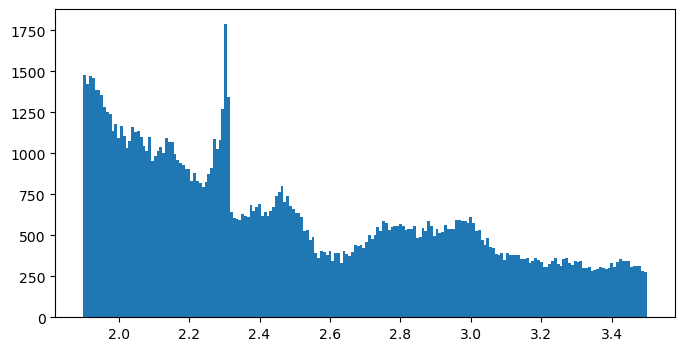

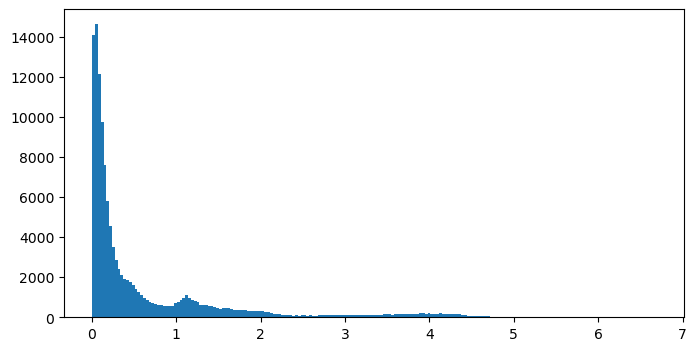

In [371]:
selz_window = (z > 1.9) & (z < 3.5)
plt.figure(figsize=(8, 4))
plt.hist(z[selz_window], 200)
plt.figure(figsize=(8, 4))
plt.hist(sig_z[selz_window], 200)
None

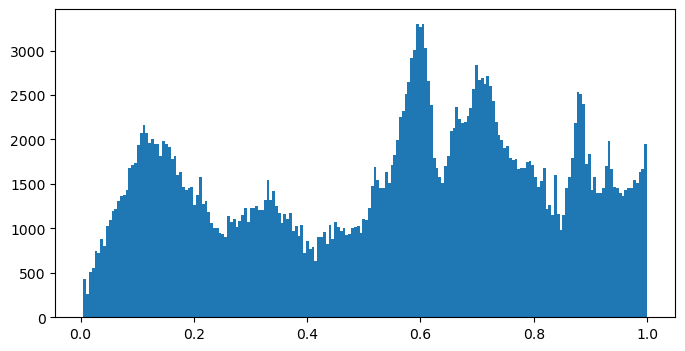

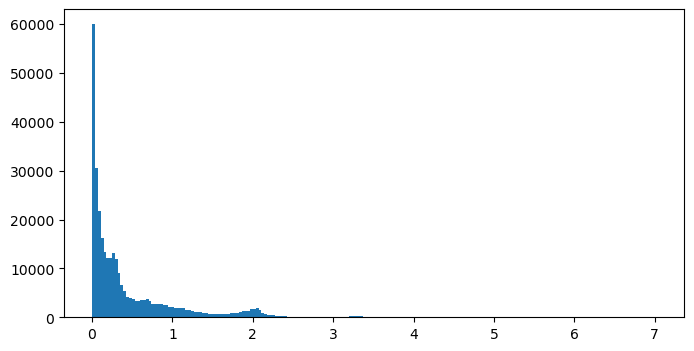

In [372]:
selz_low = (z > 0) & (z < 1)
plt.figure(figsize=(8, 4))
plt.hist(z[selz_low], 200)
plt.figure(figsize=(8, 4))
plt.hist(sig_z[selz_low], 200)
None

In [373]:
def load_hdu(path, cols=None):
    with fits.open(path, memmap=True) as h:
        t = Table(h[1].data)
    return t[cols] if cols else t

# ---- 1. the three master files, row-matched (same 784,016 rows) ----
lp = load_hdu("COSMOSWeb_mastercatalog_v1.1_lephare.fits")
cg = load_hdu("COSMOSWeb_mastercatalog_v1.1_cigale.fits")
ph = load_hdu("COSMOSWeb_mastercatalog_v1.1_photom_primary.fits")
print("rows:", len(lp), len(cg), len(ph))
assert len(lp) == len(cg) == len(ph)

# find ID / RA / DEC in the photometry file (names vary — inspect once)
print([c for c in ph.colnames if c.lower() in
       ("id","id_cosmos25","ra","dec","ra_detec","dec_detec",
        "alpha_j2000","delta_j2000")])

rows: 784016 784016 784016
['id', 'ra', 'dec']


In [374]:
ID, RA, DEC = "id", "ra", "dec"          # <-- set from the print above

cg = Table(fits.open("COSMOSWeb_mastercatalog_v1.1_cigale.fits", memmap=True)[1].data)
print("cigale mass-like cols:", [c for c in cg.colnames if "mass" in c or "ebv" in c or "sfr_inst" in c])

rename_map = {"mass": "mass_cig", "sfr_inst": "sfr_cig", "ebv_stars": "ebv_cig"}
for old, new in rename_map.items():
    if old in cg.colnames:
        cg.rename_column(old, new)

cat = hstack([ph[[ID, RA, DEC]], lp, cg])     # by row index = same galaxy

# ---- 2. redshift + per-galaxy smear kernel ----
z     = np.asarray(cat["zfinal"], float)
sig_z = (np.asarray(cat["zpdf_u68"],float) - np.asarray(cat["zpdf_l68"],float)) / 2
cat["sigma_z"]     = sig_z
cat["sigma_v_kms"] = 299792.458 * sig_z / (1 + z)
cat["dlam_rest_A"] = 1215.67 * sig_z / (1 + z)     # Lya rest-frame smearing

# ---- 3. clean to galaxies, drop stars / X-ray AGN / bad PDFs ----
is_star   = np.asarray(cat["chi_star"],float) < np.asarray(cat["zchi2"],float)  # better as star
is_xray   = np.asarray(cat["flag_chandra"], int) > 0
bad_pdf   = (sig_z < 1e-4) | ~np.isfinite(sig_z)        # the sigma_z~0 spike!
typ       = np.asarray(cat["type"], float)              # check what values mean galaxy
clean     = ~is_star & ~is_xray & ~bad_pdf & np.isfinite(z)

# ---- 4. redshift window ----
in_win = (z > 1.9) & (z < 3.5)

photo_z = cat[clean & in_win]
print(f"\nclean galaxies, 1.9<z<3.5: {len(photo_z):,}")
print(f"  removed sigma_z~0 spike: {np.sum(bad_pdf & in_win):,}")
print(f"  removed X-ray AGN:       {np.sum(is_xray & in_win):,}")

cigale mass-like cols: ['sfr_mass_vector_dir', 'sfr_mass_vector_dir_err', 'sfr_mass_vector_norm', 'sfr_mass_vector_norm_err', 'sfr_inst', 'sfr_inst_err', 'mass', 'mass_err', 'ebv_stars', 'ebv_stars_err']

clean galaxies, 1.9<z<3.5: 125,128
  removed sigma_z~0 spike: 0
  removed X-ray AGN:       193


In [375]:
C_KMS = 299792.458
SPEC_V_KMS = 150.0          # nominal spec-z error for a heterogeneous compilation
                            #   (zCOSMOS/DEIMOS/MOSDEF mix) -> set to taste

def combine_specz_photoz(photo_z, tbl_specz, zlo=1.9, zhi=3.5,
                         secure={3, 4}, id_phot="id",
                         id_spec="Id_COSMOS25", z_spec_col="specz"):
    """
    Attach secure spec-z to the photo-z sample by COSMOS2025 ID, build a
    'best redshift', and re-apply the window on z_best (which removes photo-z
    interlopers whose spec-z lands outside 1.9<z<3.5).
    Returns (combined_table, stats_dict).
    """
    # --- secure spec-z lookup keyed on COSMOS25 id ---
    base, is_bl, is_valid = decode_flags(tbl_specz["flag"])
    sec = np.isin(base, list(secure)) & is_valid & ~is_bl
    sid = np.asarray(tbl_specz[id_spec])
    sz  = np.asarray(tbl_specz[z_spec_col], float)
    ok  = sec & np.isfinite(sz) & np.isfinite(sid) & (sid > 0)
    sid = sid[ok].astype(np.int64); sz = sz[ok]

    u_ids, first = np.unique(sid, return_index=True)   # dedupe -> one z per id
    u_zs = sz[first]                                   # (unique already sorted)

    pid = np.asarray(photo_z[id_phot]).astype(np.int64)
    pos = np.clip(np.searchsorted(u_ids, pid), 0, len(u_ids) - 1)
    has_spec = u_ids[pos] == pid
    z_spec_m = np.where(has_spec, u_zs[pos], np.nan)

    # --- photo-z reliability, measured on YOUR sample ---
    zsp = z_spec_m[has_spec]
    in_win_spec = (zsp >= zlo) & (zsp <= zhi)
    interloper = ~in_win_spec                          # photo said z~2, spec disagrees
    stats = dict(
        n_phot=len(pid), n_matched=int(has_spec.sum()),
        match_frac=has_spec.mean(),
        interloper_rate=float(interloper.mean()) if has_spec.any() else np.nan,
        sigma_NMAD=1.48 * np.nanmedian(np.abs(
            (np.asarray(photo_z["zfinal"], float)[has_spec] - zsp)
            / (1 + zsp))) if has_spec.any() else np.nan,
    )

    # --- best redshift + per-galaxy smear kernel ---
    z_phot = np.asarray(photo_z["zfinal"], float)
    sig_ph = np.asarray(photo_z["sigma_z"], float)
    z_best   = np.where(has_spec, z_spec_m, z_phot)
    sig_best = np.where(has_spec, SPEC_V_KMS / C_KMS * (1 + z_best), sig_ph)
    src = np.where(has_spec, "spec", "photo")

    out = photo_z.copy()
    out["z_best"]      = z_best
    out["z_src"]       = src
    out["sigma_z_best"]   = sig_best
    out["sigma_v_best"]   = C_KMS * sig_best / (1 + z_best)
    out["has_secure_spec"] = has_spec

    # re-apply window on the BEST redshift (drops the interlopers)
    keep = (z_best >= zlo) & (z_best <= zhi) & np.isfinite(z_best)
    stats["n_after_window"] = int(keep.sum())
    return out[keep], stats


def apply_z_cuts(cat, sigz_max=0.05, nbfilt_min=None, keep_all_spec=True):
    """z-quality cut: photo rows must have sigma_z < sigz_max; spec rows kept."""
    sig = np.asarray(cat["sigma_z_best"], float)
    is_spec = np.asarray(cat["z_src"]) == "spec"
    keep = (sig < sigz_max)
    if keep_all_spec:
        keep = keep | is_spec
    if nbfilt_min is not None and "nbfilt" in cat.colnames:
        keep &= np.asarray(cat["nbfilt"], float) >= nbfilt_min
    print(f"z-cut sigma_z<{sigz_max}"
          f"{f' & nbfilt>={nbfilt_min}' if nbfilt_min else ''}: "
          f"{keep.sum():,} of {len(cat):,} "
          f"({(np.asarray(cat['z_src'])[keep]=='spec').sum():,} spec, "
          f"{(np.asarray(cat['z_src'])[keep]=='photo').sum():,} photo)")
    return cat[keep]

In [376]:
combined, stats = combine_specz_photoz(photo_z, tbl_specz, secure={2, 3, 4})
print(f"photo-z in window:        {stats['n_phot']:,}")
print(f"  with secure spec-z:     {stats['n_matched']:,} ({stats['match_frac']*100:.1f}%)")
print(f"  photo-z interloper rate: {stats['interloper_rate']*100:.1f}%  "
      f"(spec-z lands OUTSIDE 1.9–3.5)")
print(f"  measured sigma_NMAD:     {stats['sigma_NMAD']:.4f}")
print(f"after re-window on z_best: {stats['n_after_window']:,}")

final = apply_z_cuts(combined, sigz_max=0.05, nbfilt_min=None)

photo-z in window:        125,128
  with secure spec-z:     2,701 (2.2%)
  photo-z interloper rate: 17.9%  (spec-z lands OUTSIDE 1.9–3.5)
  measured sigma_NMAD:     0.0295
after re-window on z_best: 124,644
z-cut sigma_z<0.05: 18,723 of 124,644 (2,217 spec, 16,506 photo)


(array([22., 22., 27., 29., 38., 30., 29., 40., 61., 42., 35., 44., 53.,
        42., 47., 54., 54., 50., 37., 33., 41., 15., 20., 34., 25., 58.,
        30., 29., 54., 40., 53., 29., 32., 40., 54., 53., 40., 35., 50.,
        38., 27., 15., 15., 12., 10., 13., 15., 16., 11., 13., 12., 14.,
        14., 10., 12., 10.,  8., 12., 15., 17., 18., 24., 15., 11., 14.,
        12., 21., 14., 17., 16., 17., 13., 16., 10., 10.,  9., 13.,  7.,
         8.,  5., 11., 10.,  6.,  2.,  9.,  9.,  4.,  3.,  5.,  5., 10.,
         2.,  4.,  5.,  9.,  7.,  6.,  7.,  1.,  2.]),
 array([1.9001  , 1.916057, 1.932014, 1.947971, 1.963928, 1.979885,
        1.995842, 2.011799, 2.027756, 2.043713, 2.05967 , 2.075627,
        2.091584, 2.107541, 2.123498, 2.139455, 2.155412, 2.171369,
        2.187326, 2.203283, 2.21924 , 2.235197, 2.251154, 2.267111,
        2.283068, 2.299025, 2.314982, 2.330939, 2.346896, 2.362853,
        2.37881 , 2.394767, 2.410724, 2.426681, 2.442638, 2.458595,
        2.474552, 2.490509

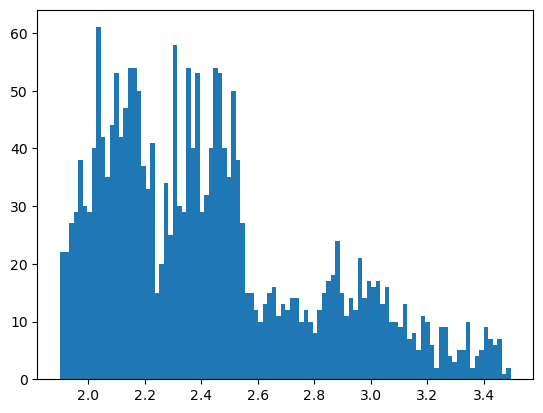

In [392]:
plt.hist(final[final['z_src'] == ['spec']]['zfinal'], 100)

In [340]:
combined2, stats2 = combine_specz_photoz(photo_z, tbl_specz, secure={2})
print(f"photo-z in window:        {stats2['n_phot']:,}")
print(f"  with secure spec-z:     {stats2['n_matched']:,} ({stats2['match_frac']*100:.1f}%)")
print(f"  photo-z interloper rate: {stats2['interloper_rate']*100:.1f}%  "
      f"(spec-z lands OUTSIDE 1.9–3.5)")
print(f"  measured sigma_NMAD:     {stats2['sigma_NMAD']:.4f}")
print(f"after re-window on z_best: {stats2['n_after_window']:,}")

final2 = apply_z_cuts(combined2, sigz_max=0.05, nbfilt_min=None)

photo-z in window:        125,128
  with secure spec-z:     1,144 (0.9%)
  photo-z interloper rate: 28.8%  (spec-z lands OUTSIDE 1.9–3.5)
  measured sigma_NMAD:     0.0441
after re-window on z_best: 124,799
z-cut sigma_z<0.05: 18,476 of 124,799 (815 spec, 17,661 photo)


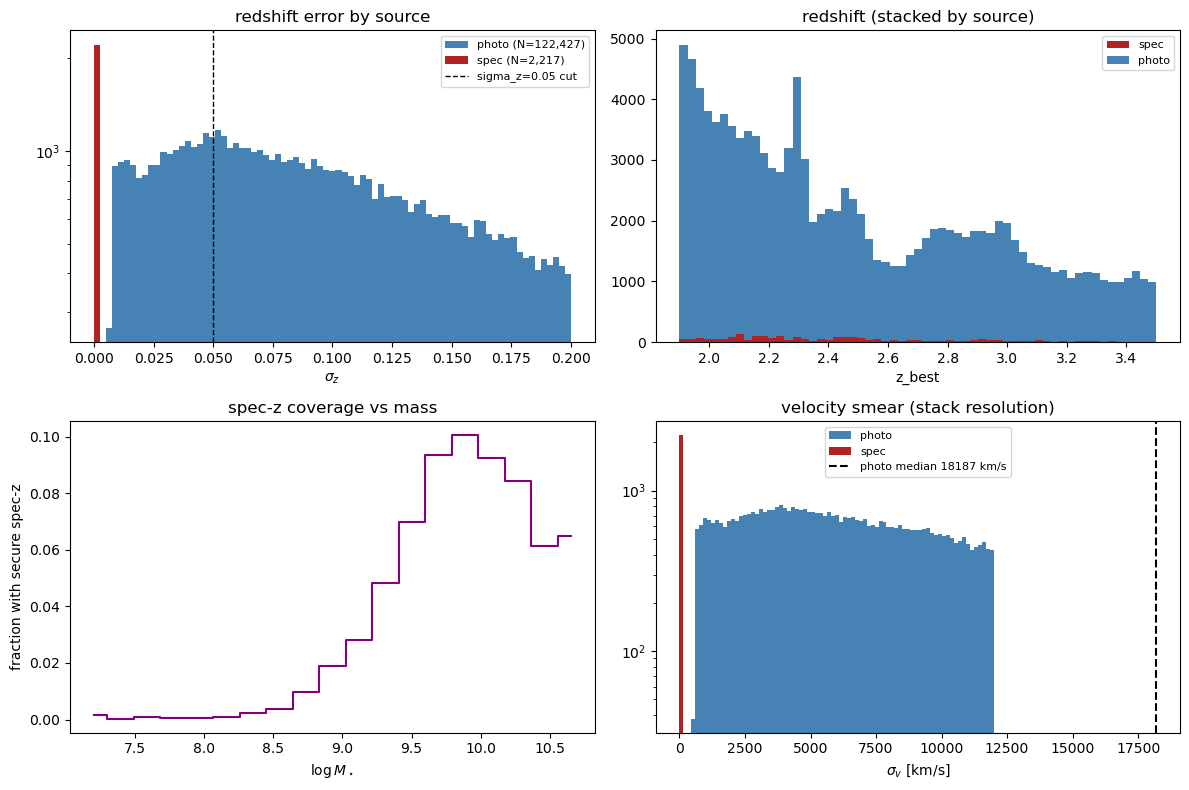

In [377]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
zb  = np.asarray(combined["z_best"], float)
sig = np.asarray(combined["sigma_z_best"], float)
spec = np.asarray(combined["z_src"]) == "spec"

# (a) sigma_z distribution, photo vs spec, with the cut line
ax[0,0].hist(sig[~spec], bins=np.linspace(0,0.2,80), color="steelblue",
             label=f"photo (N={(~spec).sum():,})")
ax[0,0].hist(sig[spec],  bins=np.linspace(0,0.2,80), color="firebrick",
             label=f"spec (N={spec.sum():,})")
ax[0,0].axvline(0.05, color="k", ls="--", lw=1, label="sigma_z=0.05 cut")
ax[0,0].set_xlabel(r"$\sigma_z$"); ax[0,0].set_yscale("log")
ax[0,0].set_title("redshift error by source"); ax[0,0].legend(fontsize=8)

# (b) z_best, stacked by source
ax[0,1].hist([zb[spec], zb[~spec]], bins=np.linspace(1.9,3.5,60), stacked=True,
             color=["firebrick","steelblue"], label=["spec","photo"])
ax[0,1].set_xlabel("z_best"); ax[0,1].set_title("redshift (stacked by source)")
ax[0,1].legend(fontsize=8)

# (c) spec-z FRACTION vs magnitude -> where does spec-z coverage exist?
mag = -2.5*np.log10(np.asarray(combined["sfr_cig"],float)*0+1)  # placeholder
mcol = "mass_med" if "mass_med" in combined.colnames else "mass_cig"
mm = np.asarray(combined[mcol], float)
edges = np.linspace(np.nanpercentile(mm,1), np.nanpercentile(mm,99), 20)
idx = np.digitize(mm, edges)
frac = [spec[idx==k].mean() if np.any(idx==k) else np.nan for k in range(1,len(edges))]
ax[1,0].step(0.5*(edges[:-1]+edges[1:]), frac, where="mid", color="purple")
ax[1,0].set_xlabel(r"$\log M_\star$"); ax[1,0].set_ylabel("fraction with secure spec-z")
ax[1,0].set_title("spec-z coverage vs mass")

# (d) velocity smear -> the effective resolution of the stack
sv = np.asarray(combined["sigma_v_best"], float)
ax[1,1].hist(sv[~spec], bins=np.linspace(0,12000,80), color="steelblue", label="photo")
ax[1,1].hist(sv[spec],  bins=np.linspace(0,12000,80), color="firebrick", label="spec")
ax[1,1].axvline(np.nanmedian(sv[~spec]), color="k", ls="--",
                label=f"photo median {np.nanmedian(sv[~spec]):.0f} km/s")
ax[1,1].set_xlabel(r"$\sigma_v$ [km/s]"); ax[1,1].set_yscale("log")
ax[1,1].set_title("velocity smear (stack resolution)"); ax[1,1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Building Samples

In [393]:
ph = Table(fits.open("COSMOSWeb_mastercatalog_v1.1_photom_primary.fits",
                     memmap=True)[1].data)

def clean_mag(m):
    m = np.asarray(m, float)
    m[(m < 0) | (m > 50)] = np.nan        # -99/99 non-detections -> NaN
    return m

# build an id -> row lookup into the photometry table
ph_id  = np.asarray(ph["id"]).astype(np.int64)
order  = np.argsort(ph_id)
ph_sorted = ph_id[order]

cmb_id = np.asarray(combined["id"]).astype(np.int64)
pos    = np.searchsorted(ph_sorted, cmb_id)
pos    = np.clip(pos, 0, len(ph_sorted) - 1)
row    = order[pos]                        # row in ph for each combined galaxy
matched = ph_sorted[pos] == cmb_id         # guard against any non-match
print(f"photometry matched: {matched.sum():,} of {len(cmb_id):,}")

for newcol, phcol in [("MAG_G", "mag_model_hsc-g"),
                      ("MAG_R", "mag_model_hsc-r"),
                      ("MAG_I", "mag_model_hsc-i")]:
    vals = clean_mag(ph[phcol][row])
    vals[~matched] = np.nan                # never assign a wrong-id magnitude
    combined[newcol] = vals

photometry matched: 124,644 of 124,644


In [394]:
def build_test_samples(combined, verbose=True):
    """
    Three cost-aware samples for staged extraction (consistent with the
    write_pipeline_catalog cell):
      A: spec-only (validation FIRST, then full spec-z science)
      B: best photo-z, spec-z-poor regime  (photo-z science pilot)
      C: best photo-z, dusty               (unique-science pilot)
    Assumes `combined` is ALREADY footprint-cut. Returns dict of subtables
    plus the boolean masks (under '_masks') for reuse.
    """
    def to_logM(x):
        x = np.asarray(x, float)
        return np.log10(x) if np.nanmedian(x) > 100 else x

    src  = np.asarray(combined["z_src"])
    sigz = np.asarray(combined["sigma_z_best"], float)
    z    = np.asarray(combined["z_best"], float)
    mcol = "mass_med" if "mass_med" in combined.colnames else "mass_cig"
    logM = to_logM(combined[mcol])
    ebvS = np.asarray(combined["ebv_minchi2"], float)          # STELLAR E(B-V)
    nbf  = (np.asarray(combined["nbfilt"], float)
            if "nbfilt" in combined.colnames else np.full(len(z), 99.))
    pdfw = (np.asarray(combined["zpdf_u68"], float)
            - np.asarray(combined["zpdf_l68"], float))

    AV_neb = 9.2 * ebvS                                        # nebular A_V (R_V=4.05, /0.44)

    is_spec   = src == "spec"
    # tightest photo-z: small error, many bands, single-peaked PDF, finite mass
    best_phot = ((~is_spec) & (sigz < 0.02) & (nbf >= 25)
                 & (pdfw < 0.05) & np.isfinite(logM))

    masks = dict(
        A = is_spec & np.isfinite(z),
        B = best_phot & (logM < 10),
        C = best_phot & (AV_neb > 1.5),
    )

    if verbose:
        labels = {"A": "A spec-only (validation+science)",
                  "B": "B best photo-z, logM<10",
                  "C": "C best photo-z, A_V(neb)>1.5"}
        for k in ("A", "B", "C"):
            print(f"{labels[k]:34s}: {masks[k].sum():,}")
        print("\ndusty-tail ladder (best photo-z only):")
        for thr in (1.0, 1.5, 2.0, 2.5):
            print(f"   A_V(neb)>{thr}: {(best_phot & (AV_neb > thr)).sum():,}")

    out = {k: combined[m] for k, m in masks.items()}
    out["_masks"] = masks
    return out

In [395]:
C_KMS = 299792.458
RA, DEC = "ra", "dec"          # set to combined's actual coord columns

# =====================================================================
# 0.  FOOTPRINT-CUT the merged sample
# =====================================================================
fib_ra, fib_dec = vdfi_fiber_positions("../../../../HETDEX-Work/vdfi/cosmos")
cra = np.asarray(combined[RA], float); cdec = np.asarray(combined[DEC], float)
cov, nearest = in_vdfi_footprint(cra, cdec, fib_ra, fib_dec,
                                 max_sep_arcsec=60.0, need_frac=None)
cmb = combined[cov]
print(f"merged sample in VDFI footprint: {cov.sum():,} of {cov.size:,}")
print(f"  median nearest-fiber: {np.median(nearest[cov]):.1f}\"  "
      f"(should be ~1-3\"; large => astrometry mismatch)")

# =====================================================================
# 1.  helpers + the three cost-aware samples
# =====================================================================
def to_logM(x):
    x = np.asarray(x, float)
    return np.log10(x) if np.nanmedian(x) > 100 else x      # auto log/linear

def flux_to_abmag(flux_mjy):
    """mJy -> AB mag (zp 16.40); non-detections / <=0 -> NaN, no warning."""
    f = np.asarray(flux_mjy, float)
    with np.errstate(invalid="ignore", divide="ignore"):
        m = -2.5*np.log10(f) + 16.40
    m[~np.isfinite(m)] = np.nan
    return m

src   = np.asarray(cmb["z_src"])
sigz  = np.asarray(cmb["sigma_z_best"], float)
z     = np.asarray(cmb["z_best"], float)
logM  = to_logM(cmb["mass_med"])
ebvS  = np.asarray(cmb["ebv_minchi2"], float)               # STELLAR E(B-V)
nbf   = np.asarray(cmb["nbfilt"], float)
pdfw  = np.asarray(cmb["zpdf_u68"],float) - np.asarray(cmb["zpdf_l68"],float)

is_spec   = src == "spec"
best_phot = (~is_spec) & (sigz < 0.02)

# nebular A_V = 9.2 * E(B-V)_stellar  (Calzetti: EBV_neb = EBV_*/0.44, R_V=4.05)
AV_neb = 9.2 * ebvS

A_spec   = is_spec & np.isfinite(z)
B_lowm   = best_phot & (logM < 10)
C_dusty  = best_phot & (AV_neb > 1.5)

print(f"\nSample A  spec-only (validation+science) : {A_spec.sum():,}")
print(f"Sample B  best photo-z, logM<10          : {B_lowm.sum():,}")
print(f"Sample C  best photo-z, A_V(neb)>1.5      : {C_dusty.sum():,}")
print("\ndusty-tail ladder (best photo-z only):")
for thr in (1.0, 1.5, 2.0, 2.5):
    print(f"   A_V(neb)>{thr}: {(best_phot & (AV_neb>thr)).sum():,}")

samples = {"A": cmb[A_spec], "B": cmb[B_lowm], "C": cmb[C_dusty]}

# =====================================================================
# 3.  WRITE launch-ready catalogs (pipeline format + columns the core run reads)
# =====================================================================
def write_pipeline_catalog(t, path, n=None, seed=42, form="ascii.ecsv",
                           field="COSMOS", catalog="lyahalo"):
    t = t.copy()
    if n is not None and len(t) > n:
        rng = np.random.default_rng(seed)
        t = t[rng.choice(len(t), n, replace=False)]
    out = Table()
    out["RA"]      = np.asarray(t[RA], float)
    out["DEC"]     = np.asarray(t[DEC], float)
    out["z"]       = np.asarray(t["z_best"], float)
    out["logM"]    = to_logM(t["mass_med"])
    out["z_src"]   = np.asarray(t["z_src"])
    out["sigma_z"] = np.asarray(t["sigma_z_best"], float)
    out["AV_neb"]  = 9.2*np.asarray(t["ebv_minchi2"], float)
    out["MAG_G"]   = np.asarray(t["MAG_G"], float)      # already AB, already cleaned
    out["MAG_R"]   = np.asarray(t["MAG_R"], float)
    out["FIELD"]   = np.full(len(t), field)
    out["CATALOG"] = np.full(len(t), catalog)
    out.write(path, overwrite=True, format=form)
    nfin = np.isfinite(out["MAG_R"]).sum()
    print(f"wrote {len(out):,} -> {path}  ({nfin:,} finite MAG_R)")
    return out

  4,612,608 good fibers of 4,612,608 (RA 149.881–150.402, DEC 2.075–2.508)
merged sample in VDFI footprint: 51,305 of 124,644
  median nearest-fiber: 0.4"  (should be ~1-3"; large => astrometry mismatch)

Sample A  spec-only (validation+science) : 1,548
Sample B  best photo-z, logM<10          : 1,573
Sample C  best photo-z, A_V(neb)>1.5      : 579

dusty-tail ladder (best photo-z only):
   A_V(neb)>1.0: 579
   A_V(neb)>1.5: 579
   A_V(neb)>2.0: 326
   A_V(neb)>2.5: 326


In [396]:
#write_pipeline_catalog(samples["A"], 'samples.ecsv')

wrote 1,548 -> samples.ecsv  (1,536 finite MAG_R)


RA,DEC,z,logM,z_src,sigma_z,AV_neb,MAG_G,MAG_R,FIELD,CATALOG
float64,float64,float64,float64,str5,float64,float64,float64,float64,str6,str7
149.88425326654445,2.1669077447261795,2.9891,8.90079,spec,0.0019959307982324224,0.9199999999999999,25.00608022517574,24.752333843314176,COSMOS,lyahalo
149.88129685668642,2.1860371774394163,1.944,9.6789,spec,0.0014730190443950394,0.9199999999999999,24.01167578801804,23.743823257208827,COSMOS,lyahalo
149.87646723296672,2.19702133875138,2.2041,10.78077,spec,0.0016031590761365984,1.8399999999999999,24.50487343479503,24.08022741600586,COSMOS,lyahalo
149.8926663257104,2.19179395329904,2.275,8.65299,spec,0.001638633617660922,0.0,25.10910622103033,25.197529410696955,COSMOS,lyahalo
149.87516683041403,2.201991157574644,1.9735,9.65122,spec,0.0014877792556075577,0.9199999999999999,24.0857954468904,23.901842575206842,COSMOS,lyahalo
149.89045401034517,2.1974849386309816,2.3757,10.1846,spec,0.001689018474240603,1.8399999999999999,24.425630229804717,23.948740307080737,COSMOS,lyahalo
149.88406943937923,2.245531569634227,2.44,8.9561,spec,0.0017211907312224646,0.9199999999999999,24.369875472908316,24.22673346012427,COSMOS,lyahalo
149.89431221215457,2.2501292252217944,2.443,9.61226,spec,0.0017226917696508562,0.9199999999999999,23.389028838425848,23.197814119752813,COSMOS,lyahalo
149.9196136430523,2.272572379654329,2.9096,9.59924,spec,0.001956153279880043,0.9199999999999999,25.043337840748336,24.300382260171748,COSMOS,lyahalo


(array([ 598.,  402.,  391.,  307.,  548., 1083.,  606.,  734.,  187.,
         231.,  182.,  104.,  163.,  416.,  296.,  184.,  120.,  178.,
         124.,  180.]),
 array([1.9003  , 1.980265, 2.06023 , 2.140195, 2.22016 , 2.300125,
        2.38009 , 2.460055, 2.54002 , 2.619985, 2.69995 , 2.779915,
        2.85988 , 2.939845, 3.01981 , 3.099775, 3.17974 , 3.259705,
        3.33967 , 3.419635, 3.4996  ]),
 <BarContainer object of 20 artists>)

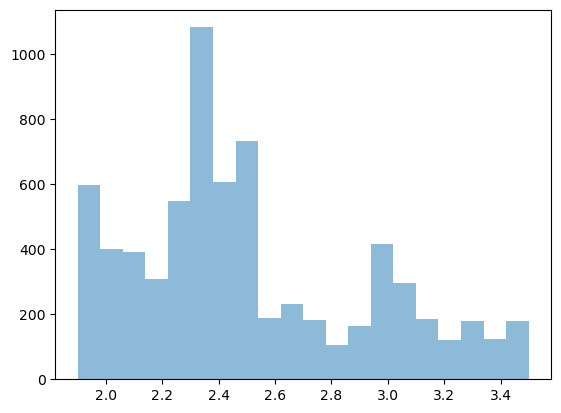

In [330]:
best_phot = (~is_spec) & (sigz < 0.05)
plt.hist(cmb[best_phot]['zfinal'], 20, alpha=0.5)

449
1974
3501
5213
7034
11237
14956


[449, 1974, 3501, 5213, 7034, 11237, 14956]

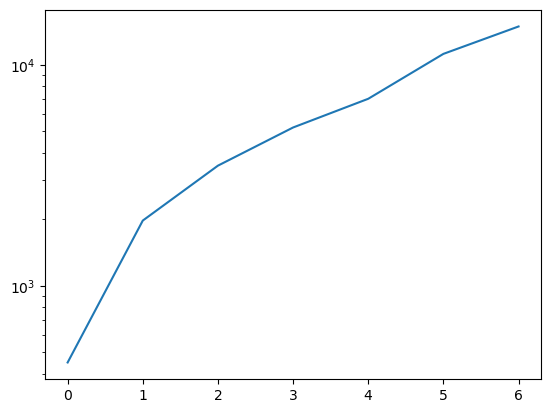

In [277]:
phot_cut1 = (~is_spec) & (sigz < 0.01)
phot_cut2 = (~is_spec) & (sigz < 0.02)
phot_cut3 = (~is_spec) & (sigz < 0.03)
phot_cut4 = (~is_spec) & (sigz < 0.04)
phot_cut5 = (~is_spec) & (sigz < 0.05)
phot_cut7p5 = (~is_spec) & (sigz < 0.075)
phot_cut10 = (~is_spec) & (sigz < 0.10)

print(len(cmb[phot_cut1]))
print(len(cmb[phot_cut2]))
print(len(cmb[phot_cut3]))
print(len(cmb[phot_cut4]))
print(len(cmb[phot_cut5]))
print(len(cmb[phot_cut7p5]))
print(len(cmb[phot_cut10]))

plt.plot([len(cmb[phot_cut1]), len(cmb[phot_cut2]), len(cmb[phot_cut3]), len(cmb[phot_cut4]), len(cmb[phot_cut5]), len(cmb[phot_cut7p5]), len(cmb[phot_cut10])])
plt.yscale('log')
[len(cmb[phot_cut1]), len(cmb[phot_cut2]), len(cmb[phot_cut3]), len(cmb[phot_cut4]), len(cmb[phot_cut5]), len(cmb[phot_cut7p5]), len(cmb[phot_cut10])]

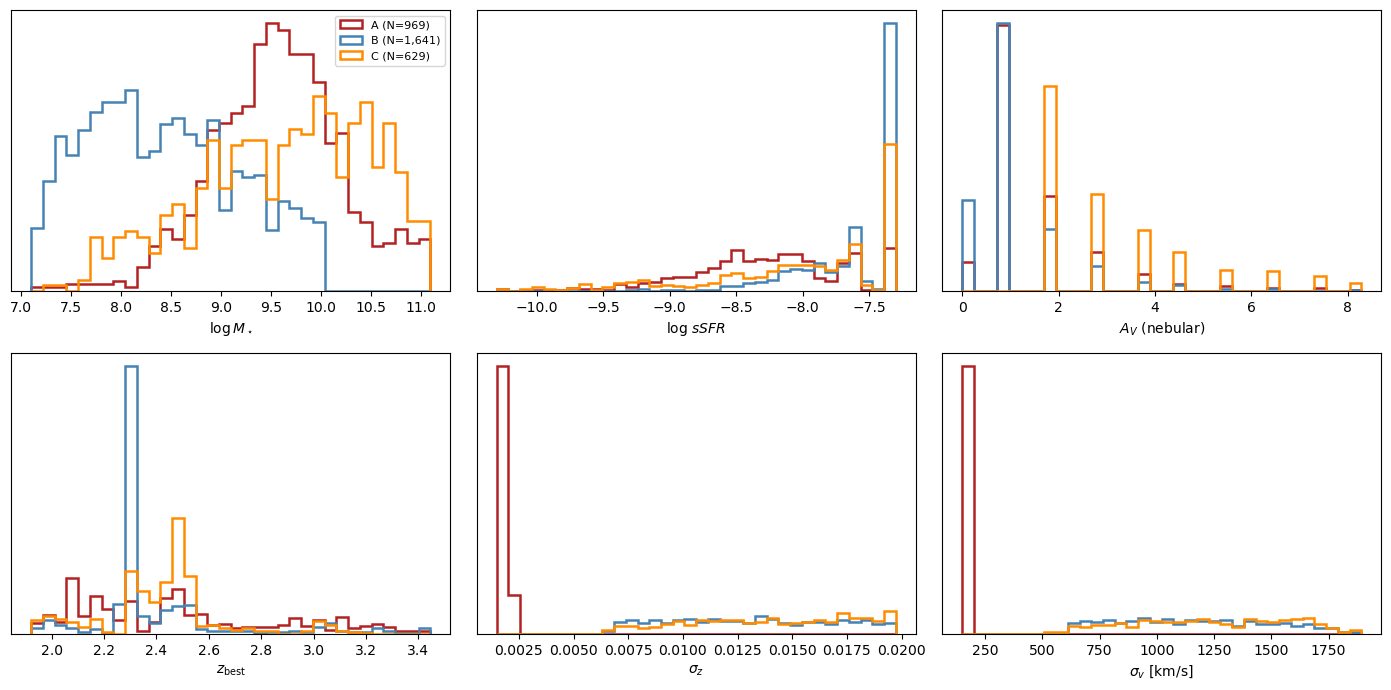

In [134]:
# =====================================================================
# 2.  plot A/B/C side by side (uniform columns)
# =====================================================================
def panels(t):
    zz = np.asarray(t["z_best"], float)
    return {
        r"$\log M_\star$":      to_logM(t["mass_med"]),
        r"$\log\,sSFR$":        np.asarray(t["ssfr_med"], float),
        r"$A_V$ (nebular)":     9.2*np.asarray(t["ebv_minchi2"], float),
        r"$z_{\rm best}$":      zz,
        r"$\sigma_z$":          np.asarray(t["sigma_z_best"], float),
        r"$\sigma_v$ [km/s]":   np.asarray(t["sigma_v_best"], float),
    }
keys = list(panels(samples["A"]).keys())
cols = {"A":"firebrick", "B":"steelblue", "C":"darkorange"}
fig, ax = plt.subplots(2, 3, figsize=(14, 7)); ax = ax.ravel()
for i, k in enumerate(keys):
    data = {s: panels(t)[k] for s, t in samples.items()}
    allv = np.concatenate([v[np.isfinite(v)] for v in data.values()])
    if allv.size == 0: continue
    edges = np.linspace(*np.nanpercentile(allv, [1, 99]), 35)
    for s, v in data.items():
        v = v[np.isfinite(v)]
        ax[i].hist(v, bins=edges, density=True, histtype="step", lw=1.8,
                   color=cols[s], label=f"{s} (N={v.size:,})")
    ax[i].set_xlabel(k); ax[i].set_yticks([])
    if i == 0: ax[i].legend(fontsize=8)
plt.tight_layout(); plt.show()

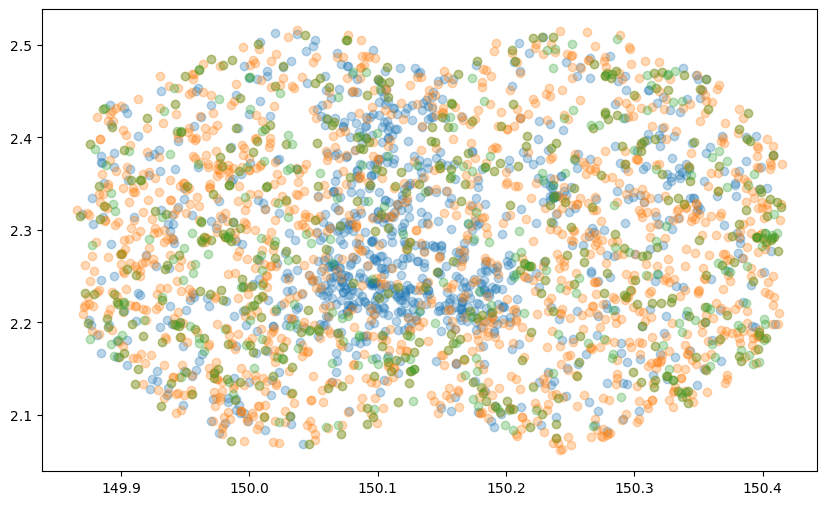

In [144]:
plt.figure(figsize=(10, 6))
plt.scatter(samples["A"]['ra'], samples["A"]['dec'], alpha=0.3)
plt.scatter(samples["B"]['ra'], samples["B"]['dec'], alpha=0.3)
plt.scatter(samples["C"]['ra'], samples["C"]['dec'], alpha=0.3)

In [146]:
# and the full spec-z science sample, ready for the real run after validation passes
table = write_pipeline_catalog(samples["A"], "cosmos_web_specz_selection.ecsv", n=None)
table

wrote 629 -> cosmos_web_photz_highdust_selection.ecsv  (603 finite MAG_R)


RA,DEC,z,logM,z_src,sigma_z,AV_neb,MAG_G,MAG_R,FIELD,CATALOG
float64,float64,float64,float64,str5,float64,float64,float64,float64,str6,str7
149.87582216016355,2.181701203604279,2.6459,10.54685,photo,0.014350000000000085,1.8399999999999999,24.970129354138894,24.87726281714393,COSMOS,lyahalo
149.87412425185775,2.198781305631432,2.51,9.55608,photo,0.01949999999999985,7.359999999999999,nan,28.98625736469433,COSMOS,lyahalo
149.8899340722141,2.194573158729399,1.9942,9.50443,photo,0.013850000000000029,1.8399999999999999,24.08073263325896,23.90194381449222,COSMOS,lyahalo
149.88922218321085,2.203799264275091,2.3874,10.38038,photo,0.018999999999999906,2.76,26.687677686045287,26.431590591929663,COSMOS,lyahalo
149.90119158397218,2.2126267165865507,2.3893,10.35949,photo,0.01949999999999985,2.76,26.056055165271935,25.612758161205154,COSMOS,lyahalo
149.89751472449072,2.2194769072075835,2.3931,8.50384,photo,0.01955000000000018,2.76,26.77398210148933,26.268691589688483,COSMOS,lyahalo
149.8965961523888,2.221942811456252,2.3063,7.99943,photo,0.012799999999999923,1.8399999999999999,27.16272214209238,27.033114071377017,COSMOS,lyahalo
149.90249491739704,2.219821953701706,1.9012,10.75019,photo,0.01794999999999991,3.6799999999999997,31.371467820201985,28.01266093933182,COSMOS,lyahalo
149.87153316202063,2.2312543845349677,2.4638,8.65275,photo,0.010600000000000165,2.76,26.819707145214263,26.182384288913493,COSMOS,lyahalo


# Testing Photometric Redshift Accuracy

(-0.05, 1.0)

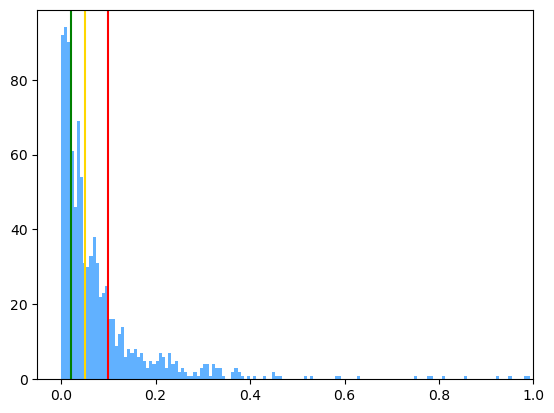

In [166]:
plt.hist(abs(samples["A"]['z_best'] - samples["A"]['zfinal']), 200, color='dodgerblue', alpha=0.7)
plt.axvline(0.1, c='r')
plt.axvline(0.05, c='gold')
plt.axvline(0.02, c='green')
plt.xlim(-0.05, 1)

In [170]:
C_KMS, LYA_REST = 299792.458, 1215.67

t = samples['A']                          # the 969-row spec table
spec   = np.asarray(t["z_src"]) == "spec"      # truth rows
z_spec = np.asarray(t["z_best"],   float)      # spec-z (truth)
z_phot = np.asarray(t["zpdf_med"], float)      # photo-z (what you'd use instead)

# guardrail: zpdf_med must NOT just equal the spec-z
print("frac z_phot == z_spec:", np.mean(z_phot[spec] == z_spec[spec]),
      "  (want ~0, NOT ~1)")

dz   = z_phot - z_spec
dv   = C_KMS   * dz / (1 + z_spec)             # km/s
dlam = LYA_REST * dz / (1 + z_spec)            # rest-frame A
m = spec & np.isfinite(dv)

bias   = np.median(dv[m])
nmad_v = 1.4826 * np.median(np.abs(dv[m] - bias))
cat    = np.mean(np.abs(dz[m] / (1 + z_spec[m])) > 0.05)   # outlier fraction
print(f"photo-z vs spec-z on {m.sum()} secure-spec galaxies:")
print(f"  bias (median dv)    = {bias:+8.0f} km/s")
print(f"  NMAD scatter        = {nmad_v:8.0f} km/s")
print(f"  median |dlam_rest|  = {np.median(np.abs(dlam[m])):8.2f} A   (window hw = 4)")
print(f"  catastrophic frac   = {cat:6.1%}  (|dz/(1+z)| > 0.05)")

frac z_phot == z_spec: 0.0   (want ~0, NOT ~1)
photo-z vs spec-z on 969 secure-spec galaxies:
  bias (median dv)    =      +84 km/s
  NMAD scatter        =     5717 km/s
  median |dlam_rest|  =    15.53 A   (window hw = 4)
  catastrophic frac   =  12.1%  (|dz/(1+z)| > 0.05)


In [290]:
N = None
core_radius = 3.5 #Arcsec
catalog_path_sz = "catalogs/lya_halo_catalog_cuts/cosmos_web_specz_selection.ecsv"
field_sz = "COSMOS"
catalog_sz = "specz"

LYA_REST = 1215.67
cfg_specz = replace(cfg, 
    num_gal         = N,
    field           = field_sz,
    catalog         = catalog_sz,
    catalog_path    = catalog_path_sz,
    bins            = [0, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0],
    bin_mode        = "virial",
    mask_method     = "image",
    mass_col        = "MASS_50",
    z_col           = "z_phot",  
    mask_percentile = 90,
    bg_inner_arcsec = 57.0,
    bg_outer_arcsec = 63.0,
    min_bg_fibers   = 25,
    smooth_bg       = True,
    smoothing_values = [200, 20, 300],
    fiber_combine_method   = "biweight",
    rest_delta      = 0.2,
    rest_wave_min   = 900,
    rest_wave_max   = 1800,
    rest_density    = True,
    cut_radial_bin  = 5,
    min_good_wave   = 100,
    combine_wave_block = 32,
    line_window = [LYA_REST-4, LYA_REST+4],
    n_bootstrap = 1000)

In [283]:
prod_specz_photz = core.read_core_fits("outputs_core/6-27-26-core_extraction_cosmosweb_specz.fits")
prod_specz_photz['catalog']['z_phot'] = samples['A']['zpdf_med']
prod_specz_photz['catalog']['z_err'] = samples['A']['sigma_z']
prod_specz_photz['catalog']

RA,DEC,z,MASS_50,MAG_G,MAG_R,AV_neb,z_src,sigma_z,FIELD,CATALOG,z_phot,z_err
float64,float64,float64,float64,float64,float64,float64,str4,float64,str6,str9,float64,float64
149.88425326654445,2.1669077447261795,2.9891,8.90079,25.00608022517574,24.752333843314176,0.9199999999999999,spec,0.0019959307982324224,COSMOS,specz_val,2.9296,0.04674999999999985
149.88129685668642,2.1860371774394163,1.944,9.6789,24.01167578801804,23.743823257208827,0.9199999999999999,spec,0.0014730190443950394,COSMOS,specz_val,2.1637,0.034049999999999914
149.87646723296672,2.19702133875138,2.2041,10.78077,24.50487343479503,24.08022741600586,1.8399999999999999,spec,0.0016031590761365984,COSMOS,specz_val,2.1606,0.026900000000000146
149.87516683041403,2.201991157574644,1.9735,9.65122,24.0857954468904,23.901842575206842,0.9199999999999999,spec,0.0014877792556075577,COSMOS,specz_val,2.086,0.025899999999999812
149.89045401034517,2.1974849386309816,2.3757,10.1846,24.425630229804717,23.948740307080737,1.8399999999999999,spec,0.001689018474240603,COSMOS,specz_val,2.255,0.06000000000000005
149.88406943937923,2.245531569634227,2.44,8.9561,24.369875472908316,24.22673346012427,0.9199999999999999,spec,0.0017211907312224646,COSMOS,specz_val,2.3972,0.021199999999999886
149.89431221215457,2.2501292252217944,2.443,9.61226,23.389028838425848,23.197814119752813,0.9199999999999999,spec,0.0017226917696508562,COSMOS,specz_val,2.4672,0.010650000000000048
149.9196136430523,2.272572379654329,2.9096,9.59924,25.043337840748336,24.300382260171748,0.9199999999999999,spec,0.001956153279880043,COSMOS,specz_val,3.0297,0.0484
149.9766579329696,2.080738031349212,2.0096,9.63645,24.057638656376106,23.930702746883764,0.9199999999999999,spec,0.0015058417513625375,COSMOS,specz_val,2.0179,0.023450000000000082


689
969



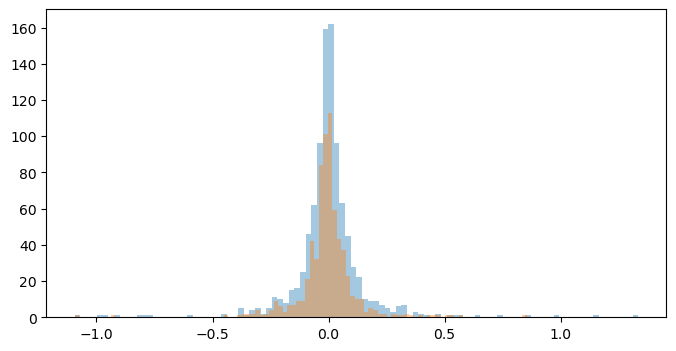

In [309]:
conf_cut = prod_specz_photz['catalog']['z_err'] < 0.05
print(len(prod_specz_photz['catalog'][conf_cut]))
print(len(prod_specz_photz['catalog']))

dz_true = prod_specz_photz['catalog']['z'] - prod_specz_photz['catalog']['z_phot']

plt.figure(figsize=(8, 4))
plt.hist(dz_true, 100, alpha=0.4)
plt.hist(dz_true[conf_cut], 100, alpha=0.4)
print()

In [310]:
stack_specz = core.build_core_stacks(cfg_specz, prod_specz_photz, mask=conf_cut, output="flux")

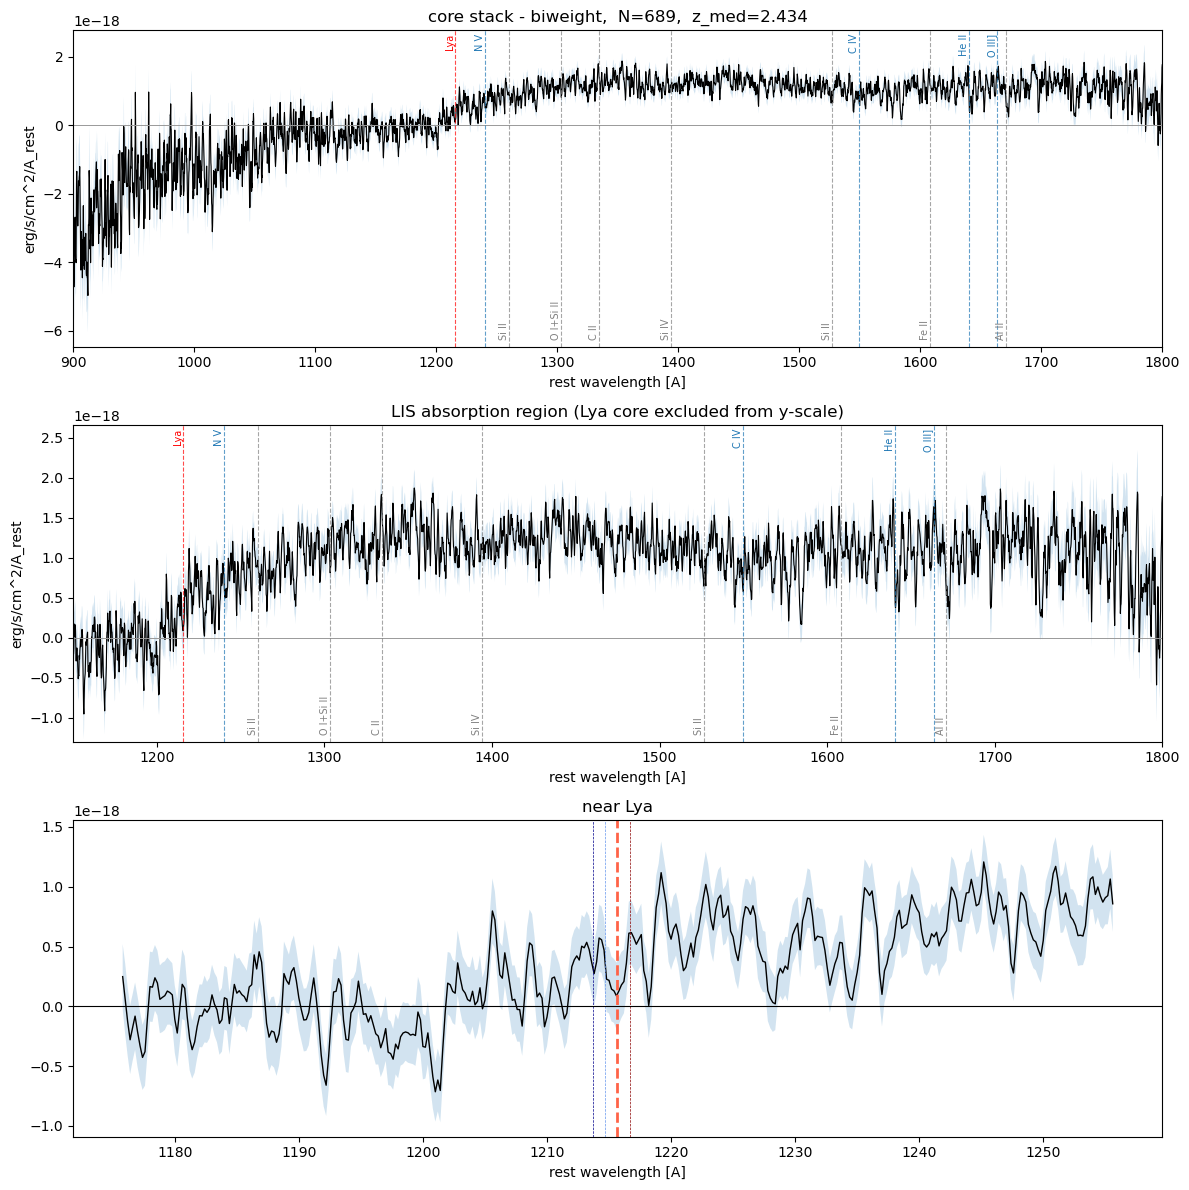

In [333]:
plotting.plot_core_stack(stack_specz, method="biweight")

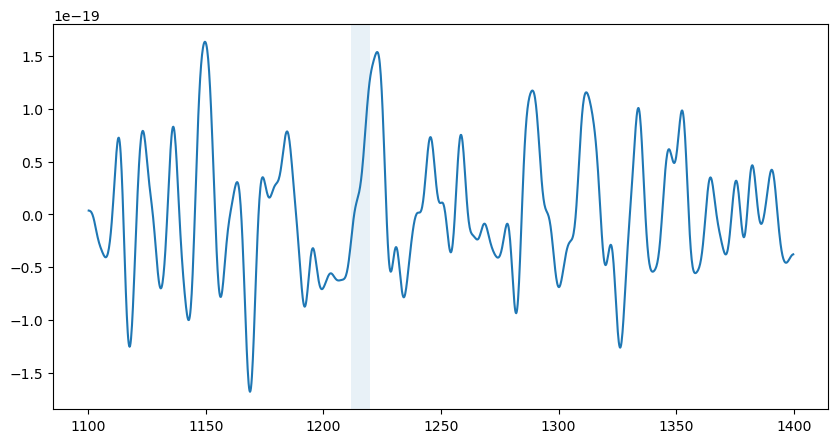

In [212]:
xcuts = (stack_specz['rest_wave'] > 1100) & (stack_specz['rest_wave'] < 1400)
smoothed = gaussian_filter1d(stack_specz['stacks']['biweight']['flux'][xcuts], 50)

plt.figure(figsize=(10, 5))
plt.plot(stack_specz['rest_wave'][xcuts], gaussian_filter1d(stack_specz['stacks']['biweight']['flux'][xcuts], 10)-smoothed)
plt.axvspan(1211.67, 1219.67, alpha=0.1)

# Catalog Cuts

In [412]:
catalog_keep = Table.read('catalogs/lya_halo_catalog_cuts/lya_mosdef_catalog_KEEP.fits', format='fits')
catalog_keep[:5]

INDEX,FIELD,CATALOG,ID,ID_V21,ID_V41,MASKNAME,SLITOBJNAME,RA,DEC,z,Z_QUAL,HA_FLUX,HA_FLUX_ERR,HA_FWHM,HA_FWHM_ERR,HB_FLUX,HB_FLUX_ERR,HB_FWHM,HB_FWHM_ERR,HG_FLUX,HG_FLUX_ERR,HG_FWHM,HG_FWHM_ERR,HD_FLUX,HD_FLUX_ERR,HD_FWHM,HD_FWHM_ERR,OII3727_FLUX,OII3727_FLUX_ERR,OII3727_FWHM,OII3727_FWHM_ERR,OII3730_FLUX,OII3730_FLUX_ERR,OII3730_FWHM,OII3730_FWHM_ERR,OIII4364_FLUX,OIII4364_FLUX_ERR,OIII4364_FWHM,OIII4364_FWHM_ERR,OIII4960_FLUX,OIII4960_FLUX_ERR,OIII4960_FWHM,OIII4960_FWHM_ERR,OIII5008_FLUX,OIII5008_FLUX_ERR,OIII5008_FWHM,OIII5008_FWHM_ERR,OI6302_FLUX,OI6302_FLUX_ERR,OI6302_FWHM,OI6302_FWHM_ERR,NII6550_FLUX,NII6550_FLUX_ERR,NII6550_FWHM,NII6550_FWHM_ERR,NII6585_FLUX,NII6585_FLUX_ERR,NII6585_FWHM,NII6585_FWHM_ERR,SII6718_FLUX,SII6718_FLUX_ERR,SII6718_FWHM,SII6718_FWHM_ERR,SII6733_FLUX,SII6733_FLUX_ERR,SII6733_FWHM,SII6733_FWHM_ERR,NEIII3870_FLUX,NEIII3870_FLUX_ERR,NEIII3870_FWHM,NEIII3870_FWHM_ERR,NEIII3969_FLUX,NEIII3969_FLUX_ERR,NEIII3969_FWHM,NEIII3969_FWHM_ERR,NIIHA,NIIHA_ERR,MASS_50,MASS_16,MASS_84,SFR_50,SFR_16,SFR_84,SSFR_50,SSFR_16,SSFR_84,AV_50,AV_16,AV_84,AGE_50,AGE_16,AGE_84,TAU_50,TAU_16,TAU_84,CHI2,ZFAST,EBV_STAR_16,EBV_STAR_50,EBV_STAR_84,HA_SN,HA_FLAG,HB_SN,HB_FLAG,HG_SN,HG_FLAG,HD_SN,HD_FLAG,OII3727_SN,OII3727_FLAG,OII3730_SN,OII3730_FLAG,OIII4364_SN,OIII4364_FLAG,OIII4960_SN,OIII4960_FLAG,OIII5008_SN,OIII5008_FLAG,OI6302_SN,OI6302_FLAG,NII6550_SN,NII6550_FLAG,NII6585_SN,NII6585_FLAG,SII6718_SN,SII6718_FLAG,SII6733_SN,SII6733_FLAG,NEIII3870_SN,NEIII3870_FLAG,NEIII3969_SN,NEIII3969_FLAG,O3,O3_ERR,O32,O32_ERR,EBV_NEB_16,EBV_NEB_50,EBV_NEB_84,FLUX_RADIUS,A_IMAGE,B_IMAGE,THETA_J2000,KRON_RADIUS,FWHM_IMAGE,CLASS_STAR,F_F160W,E_F160W,F_F814W,E_F814W,F_F606W,E_F606W,F_G,E_G,F_R,E_R,F_V,E_V,F_IRAC1,E_IRAC1,IRAC1_CONTAM,F_IRAC2,E_IRAC2,IRAC2_CONTAM,F_IRAC3,E_IRAC3,IRAC3_CONTAM,F_IRAC4,E_IRAC4,IRAC4_CONTAM,USE_PHOT,STAR_FLAG,PHOT_FLAGS,Z_SPEC,TOT_COR,SKELTON_MATCH,BA,INCL_DEG,GALFIT_FLAG_F160W,GALFIT_MAG_F160W,GALFIT_MAG_ERR_F160W,RE_F160W,RE_ERR_F160W,N_F160W,N_ERR_F160W,Q_F160W,Q_ERR_F160W,PA_F160W,PA_ERR_F160W,SN_F160W,VDW_MATCH_F160W,GALFIT_FLAG_F125W,GALFIT_MAG_F125W,GALFIT_MAG_ERR_F125W,RE_F125W,RE_ERR_F125W,N_F125W,N_ERR_F125W,Q_F125W,Q_ERR_F125W,PA_F125W,PA_ERR_F125W,SN_F125W,VDW_MATCH_F125W,RE_BEST,RE_BEST_SRC,Q_BEST,Q_BEST_SRC,RE_CIRC_BEST,MAG_G,MAG_R,MAG_V,MAG_F606W,MAG_F814W,MAG_F160W,GR_COLOR,Z_SECURE,Z_INWINDOW,BEST_LINE_SN,LINE_SN_OK,COORDS_OK,SAMPLE,HAS_DUP_0p5AS,DUP_DROP,BLEND_DROP,BLEND_MERGE,KEEP,XRAY_MATCH,XRAY_SEP_AS,XRAY_NAME,XRAY_FLUX_B,XRAY_SIG,AGN_XRAY,NIIHA_OK,BPT_O3HB,BPT_N2HA,AGN_OPT_USABLE,AGN_OPT,DONLEY_X,DONLEY_Y,AGN_IR_USABLE,AGN_IR,AGN_FLAG,CLEAN,MEX_O3HB,AGN_MEX,MEX_INTERMED,AGN_MEX_USABLE,AGN_MEX_APPLIED,VALID,EBV
int64,bytes6,bytes6,int64,int64,int64,bytes8,int64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,f

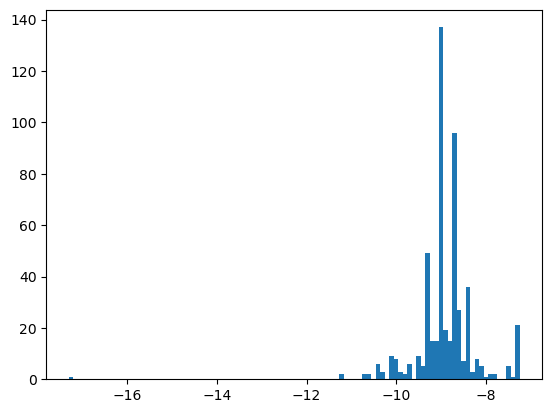

41


INDEX,FIELD,CATALOG,ID,ID_V21,ID_V41,MASKNAME,SLITOBJNAME,RA,DEC,z,Z_QUAL,HA_FLUX,HA_FLUX_ERR,HA_FWHM,HA_FWHM_ERR,HB_FLUX,HB_FLUX_ERR,HB_FWHM,HB_FWHM_ERR,HG_FLUX,HG_FLUX_ERR,HG_FWHM,HG_FWHM_ERR,HD_FLUX,HD_FLUX_ERR,HD_FWHM,HD_FWHM_ERR,OII3727_FLUX,OII3727_FLUX_ERR,OII3727_FWHM,OII3727_FWHM_ERR,OII3730_FLUX,OII3730_FLUX_ERR,OII3730_FWHM,OII3730_FWHM_ERR,OIII4364_FLUX,OIII4364_FLUX_ERR,OIII4364_FWHM,OIII4364_FWHM_ERR,OIII4960_FLUX,OIII4960_FLUX_ERR,OIII4960_FWHM,OIII4960_FWHM_ERR,OIII5008_FLUX,OIII5008_FLUX_ERR,OIII5008_FWHM,OIII5008_FWHM_ERR,OI6302_FLUX,OI6302_FLUX_ERR,OI6302_FWHM,OI6302_FWHM_ERR,NII6550_FLUX,NII6550_FLUX_ERR,NII6550_FWHM,NII6550_FWHM_ERR,NII6585_FLUX,NII6585_FLUX_ERR,NII6585_FWHM,NII6585_FWHM_ERR,SII6718_FLUX,SII6718_FLUX_ERR,SII6718_FWHM,SII6718_FWHM_ERR,SII6733_FLUX,SII6733_FLUX_ERR,SII6733_FWHM,SII6733_FWHM_ERR,NEIII3870_FLUX,NEIII3870_FLUX_ERR,NEIII3870_FWHM,NEIII3870_FWHM_ERR,NEIII3969_FLUX,NEIII3969_FLUX_ERR,NEIII3969_FWHM,NEIII3969_FWHM_ERR,NIIHA,NIIHA_ERR,MASS_50,MASS_16,MASS_84,SFR_50,SFR_16,SFR_84,SSFR_50,SSFR_16,SSFR_84,AV_50,AV_16,AV_84,AGE_50,AGE_16,AGE_84,TAU_50,TAU_16,TAU_84,CHI2,ZFAST,EBV_STAR_16,EBV_STAR_50,EBV_STAR_84,HA_SN,HA_FLAG,HB_SN,HB_FLAG,HG_SN,HG_FLAG,HD_SN,HD_FLAG,OII3727_SN,OII3727_FLAG,OII3730_SN,OII3730_FLAG,OIII4364_SN,OIII4364_FLAG,OIII4960_SN,OIII4960_FLAG,OIII5008_SN,OIII5008_FLAG,OI6302_SN,OI6302_FLAG,NII6550_SN,NII6550_FLAG,NII6585_SN,NII6585_FLAG,SII6718_SN,SII6718_FLAG,SII6733_SN,SII6733_FLAG,NEIII3870_SN,NEIII3870_FLAG,NEIII3969_SN,NEIII3969_FLAG,O3,O3_ERR,O32,O32_ERR,EBV_NEB_16,EBV_NEB_50,EBV_NEB_84,FLUX_RADIUS,A_IMAGE,B_IMAGE,THETA_J2000,KRON_RADIUS,FWHM_IMAGE,CLASS_STAR,F_F160W,E_F160W,F_F814W,E_F814W,F_F606W,E_F606W,F_G,E_G,F_R,E_R,F_V,E_V,F_IRAC1,E_IRAC1,IRAC1_CONTAM,F_IRAC2,E_IRAC2,IRAC2_CONTAM,F_IRAC3,E_IRAC3,IRAC3_CONTAM,F_IRAC4,E_IRAC4,IRAC4_CONTAM,USE_PHOT,STAR_FLAG,PHOT_FLAGS,Z_SPEC,TOT_COR,SKELTON_MATCH,BA,INCL_DEG,GALFIT_FLAG_F160W,GALFIT_MAG_F160W,GALFIT_MAG_ERR_F160W,RE_F160W,RE_ERR_F160W,N_F160W,N_ERR_F160W,Q_F160W,Q_ERR_F160W,PA_F160W,PA_ERR_F160W,SN_F160W,VDW_MATCH_F160W,GALFIT_FLAG_F125W,GALFIT_MAG_F125W,GALFIT_MAG_ERR_F125W,RE_F125W,RE_ERR_F125W,N_F125W,N_ERR_F125W,Q_F125W,Q_ERR_F125W,PA_F125W,PA_ERR_F125W,SN_F125W,VDW_MATCH_F125W,RE_BEST,RE_BEST_SRC,Q_BEST,Q_BEST_SRC,RE_CIRC_BEST,MAG_G,MAG_R,MAG_V,MAG_F606W,MAG_F814W,MAG_F160W,GR_COLOR,Z_SECURE,Z_INWINDOW,BEST_LINE_SN,LINE_SN_OK,COORDS_OK,SAMPLE,HAS_DUP_0p5AS,DUP_DROP,BLEND_DROP,BLEND_MERGE,KEEP,XRAY_MATCH,XRAY_SEP_AS,XRAY_NAME,XRAY_FLUX_B,XRAY_SIG,AGN_XRAY,NIIHA_OK,BPT_O3HB,BPT_N2HA,AGN_OPT_USABLE,AGN_OPT,DONLEY_X,DONLEY_Y,AGN_IR_USABLE,AGN_IR,AGN_FLAG,CLEAN,MEX_O3HB,AGN_MEX,MEX_INTERMED,AGN_MEX_USABLE,AGN_MEX_APPLIED,VALID,EBV
int64,bytes6,bytes6,int64,int64,int64,bytes8,int64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,f

In [436]:
plt.hist(catalog_keep['SSFR_50'], 100)
plt.show()

cut_sSFR = (catalog_keep['SSFR_50'] < -9.5)
cut_agn = prod["catalog"]["CLEAN"]

cut_quenched = cut_agn & cut_sSFR

catalog_keep_quenched = catalog_keep[cut_quenched]
print(len(catalog_keep_quenched))
catalog_keep_quenched[:5]

In [445]:
prod_egs    = core.read_core_fits("outputs_core/6-23-26-core_extraction_egs_MF.fits")
prod_cosmos = core.read_core_fits("outputs_core/6-23-26-core_extraction_cosmos_MF.fits")

prod_core = stack.concat_core_prods(prod_egs, prod_cosmos)
print(f"pooled {prod_core['n_per_input']} -> {len(prod_core['core_spec'])} galaxies")

pooled [244, 278] -> 522 galaxies


In [446]:
stack_quenched = core.build_core_stacks(cfg, prod_core, mask=cut_quenched, output="flux")

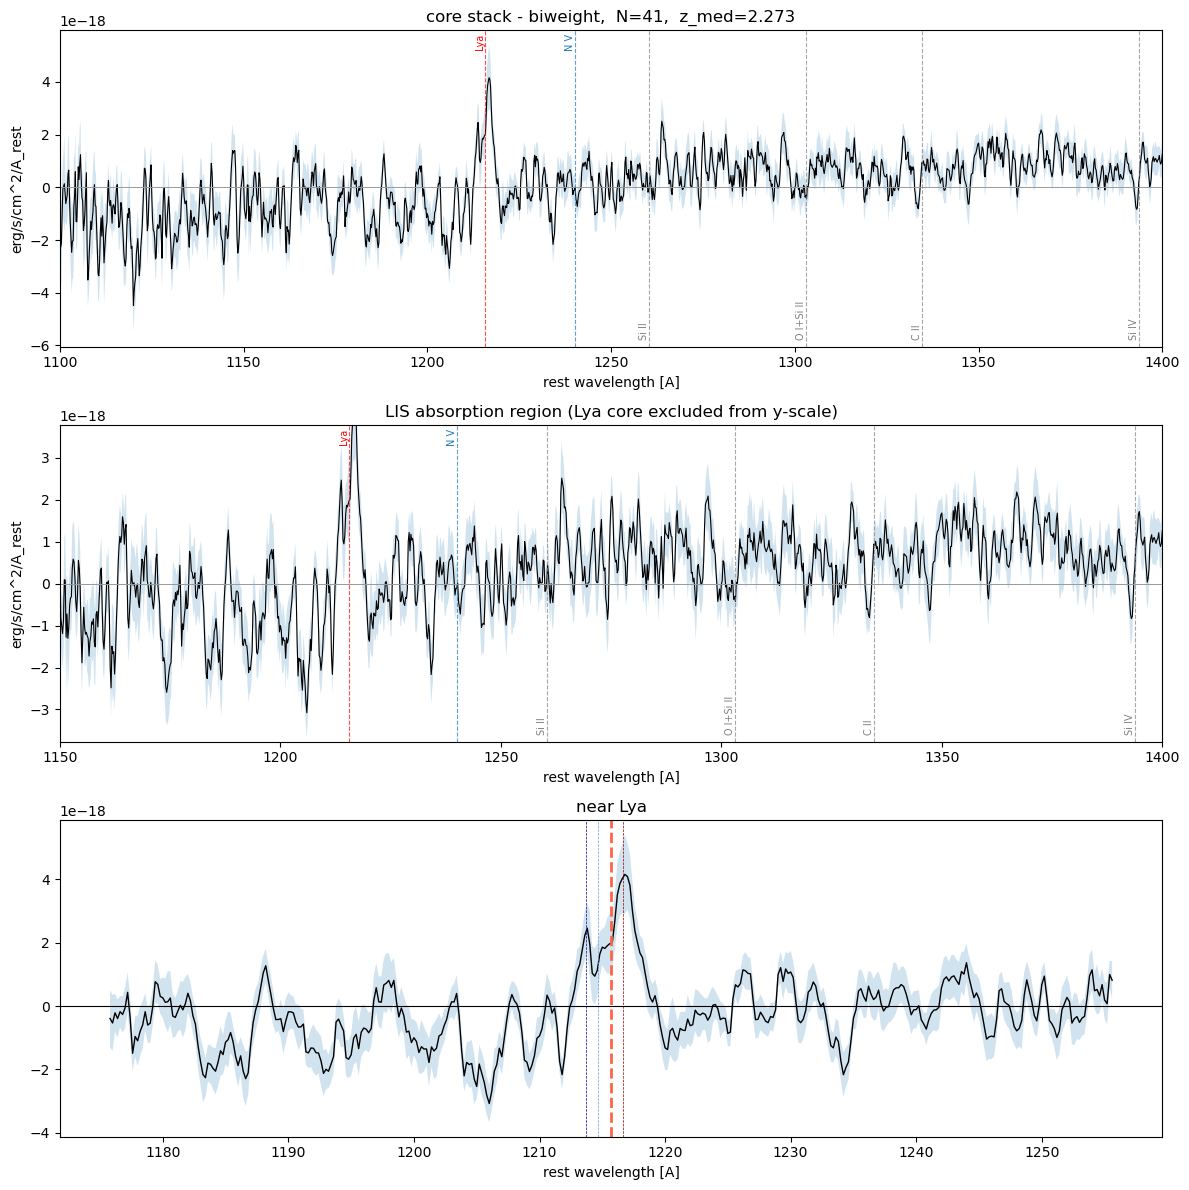

In [439]:
plotting.plot_core_stack(stack_quenched, method="biweight")

In [444]:
random_seed = 10
split_col = 'MASS_50'
scale = 'kpc'
half_width = 3.5
vr_approx = 90

cfg_prod = replace(cfg, 
                   field='BOTH',
                   rest_wave_min=1100,
                   rest_wave_max=1400,
                   n_bootstrap=500,
                   #flux_unit='flux_arcsec2',
                   #rest_density=False,
                   line_window=[LYA_REST-half_width, LYA_REST+half_width])

# load and cut your mega-product as normal
if (scale.lower() == 'virial'):
    product1 = read_galaxy_fits('./outputs/galaxy_catc1488c_b8_8c91de_AEGIS_MOSDEF_virial_biweight_image_bg57-63.fits')
    product2 = read_galaxy_fits('./outputs/galaxy_catc1488c_b8_8c91de_COSMOS_MOSDEF_virial_biweight_image_bg57-63.fits')
elif (scale.lower() == 'kpc'):
    product1 = read_galaxy_fits('./outputs/galaxy_catc1488c_b8_87bd55_AEGIS_MOSDEF_kpc_biweight_image_bg57-63.fits')
    product2 = read_galaxy_fits('./outputs/galaxy_catc1488c_b8_87bd55_COSMOS_MOSDEF_kpc_biweight_image_bg57-63.fits')
else:
    print('Wrong input or \'other\' not yet implemented')

product1 = apply_finite_cut(product1, cfg_prod.cut_radial_bin, cfg_prod.min_good_wave)
product2 = apply_finite_cut(product2, cfg_prod.cut_radial_bin, cfg_prod.min_good_wave)

# combine into one product -- tags each galaxy with its source in column "SUBSET"
mega = multicat.combine_products(
    {"cat1": product1, "cat2": product2},
    label_col="SUBSET")

Finite-spectrum cut (bin 7, > 100 px): kept 230 / 248 galaxies
Finite-spectrum cut (bin 7, > 100 px): kept 276 / 280 galaxies
combined 2 products -> 506 galaxies (origin in column 'SUBSET')


In [482]:
# carry SSFR_50 from cat_core onto mega using the match
ssfr = np.full(mega.ngal, np.nan)
ssfr[matched] = np.asarray(cat_core['SSFR_50'], dtype=float)[idx[matched]]
mega.catalog['SSFR_50'] = ssfr
print(f"{np.isfinite(ssfr).sum()}/{mega.ngal} have SSFR_50")

groups = multicat.split_product_by(
    mega, 'SSFR_50',
    edges=[-np.inf, -9.5, np.inf],
    labels=['low_sSFR', 'high_sSFR'])

491/506 have SSFR_50
  SSFR_50 low_sSFR: 47 galaxies
  SSFR_50 high_sSFR: 444 galaxies


In [483]:
stacks = multicat.stack_each(cfg, groups, keep_cube=True)

Capping logMstar 11.37 -> 11.00, z=2.163
Capping logMstar 11.01 -> 11.00, z=2.296
Capping logMstar 11.34 -> 11.00, z=2.297
Capping logMstar 11.34 -> 11.00, z=2.297
Capping logMstar 11.04 -> 11.00, z=2.187
Capping logMstar 11.18 -> 11.00, z=2.292
Capping logMstar 11.28 -> 11.00, z=2.365
Capping logMstar 11.29 -> 11.00, z=2.191
Capping logMstar 11.11 -> 11.00, z=2.442
Capping logMstar 11.74 -> 11.00, z=2.447
Capping logMstar 11.23 -> 11.00, z=2.465
Capping logMstar 11.19 -> 11.00, z=2.468
Capping logMstar 11.23 -> 11.00, z=2.471
Capping logMstar 11.63 -> 11.00, z=2.487
Capping logMstar 11.30 -> 11.00, z=2.446
Capping logMstar 11.08 -> 11.00, z=3.179


Capping logMstar 11.21 -> 11.00, z=2.471
Capping logMstar 11.18 -> 11.00, z=2.114
Capping logMstar 11.07 -> 11.00, z=2.475
Capping logMstar 11.06 -> 11.00, z=2.562
Capping logMstar 11.43 -> 11.00, z=2.102
Capping logMstar 11.06 -> 11.00, z=2.472
Capping logMstar 11.06 -> 11.00, z=2.479


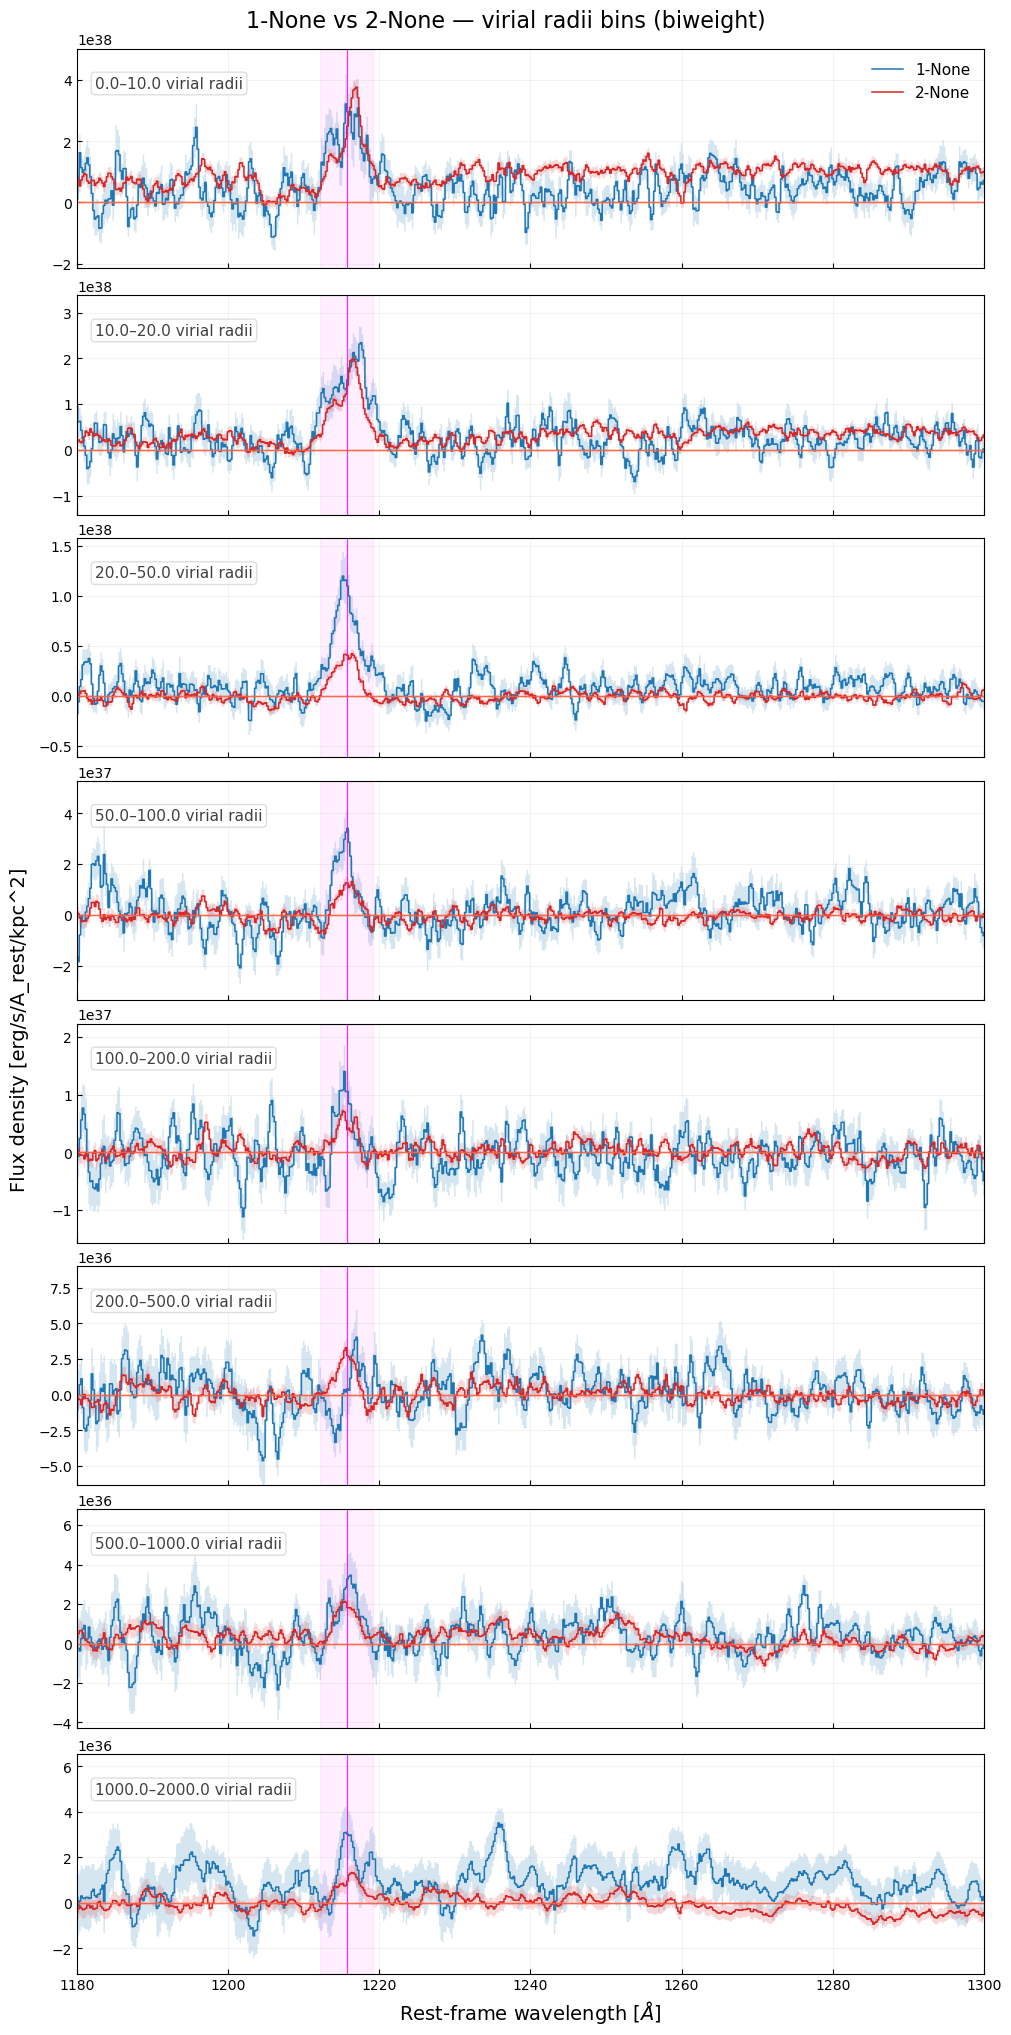

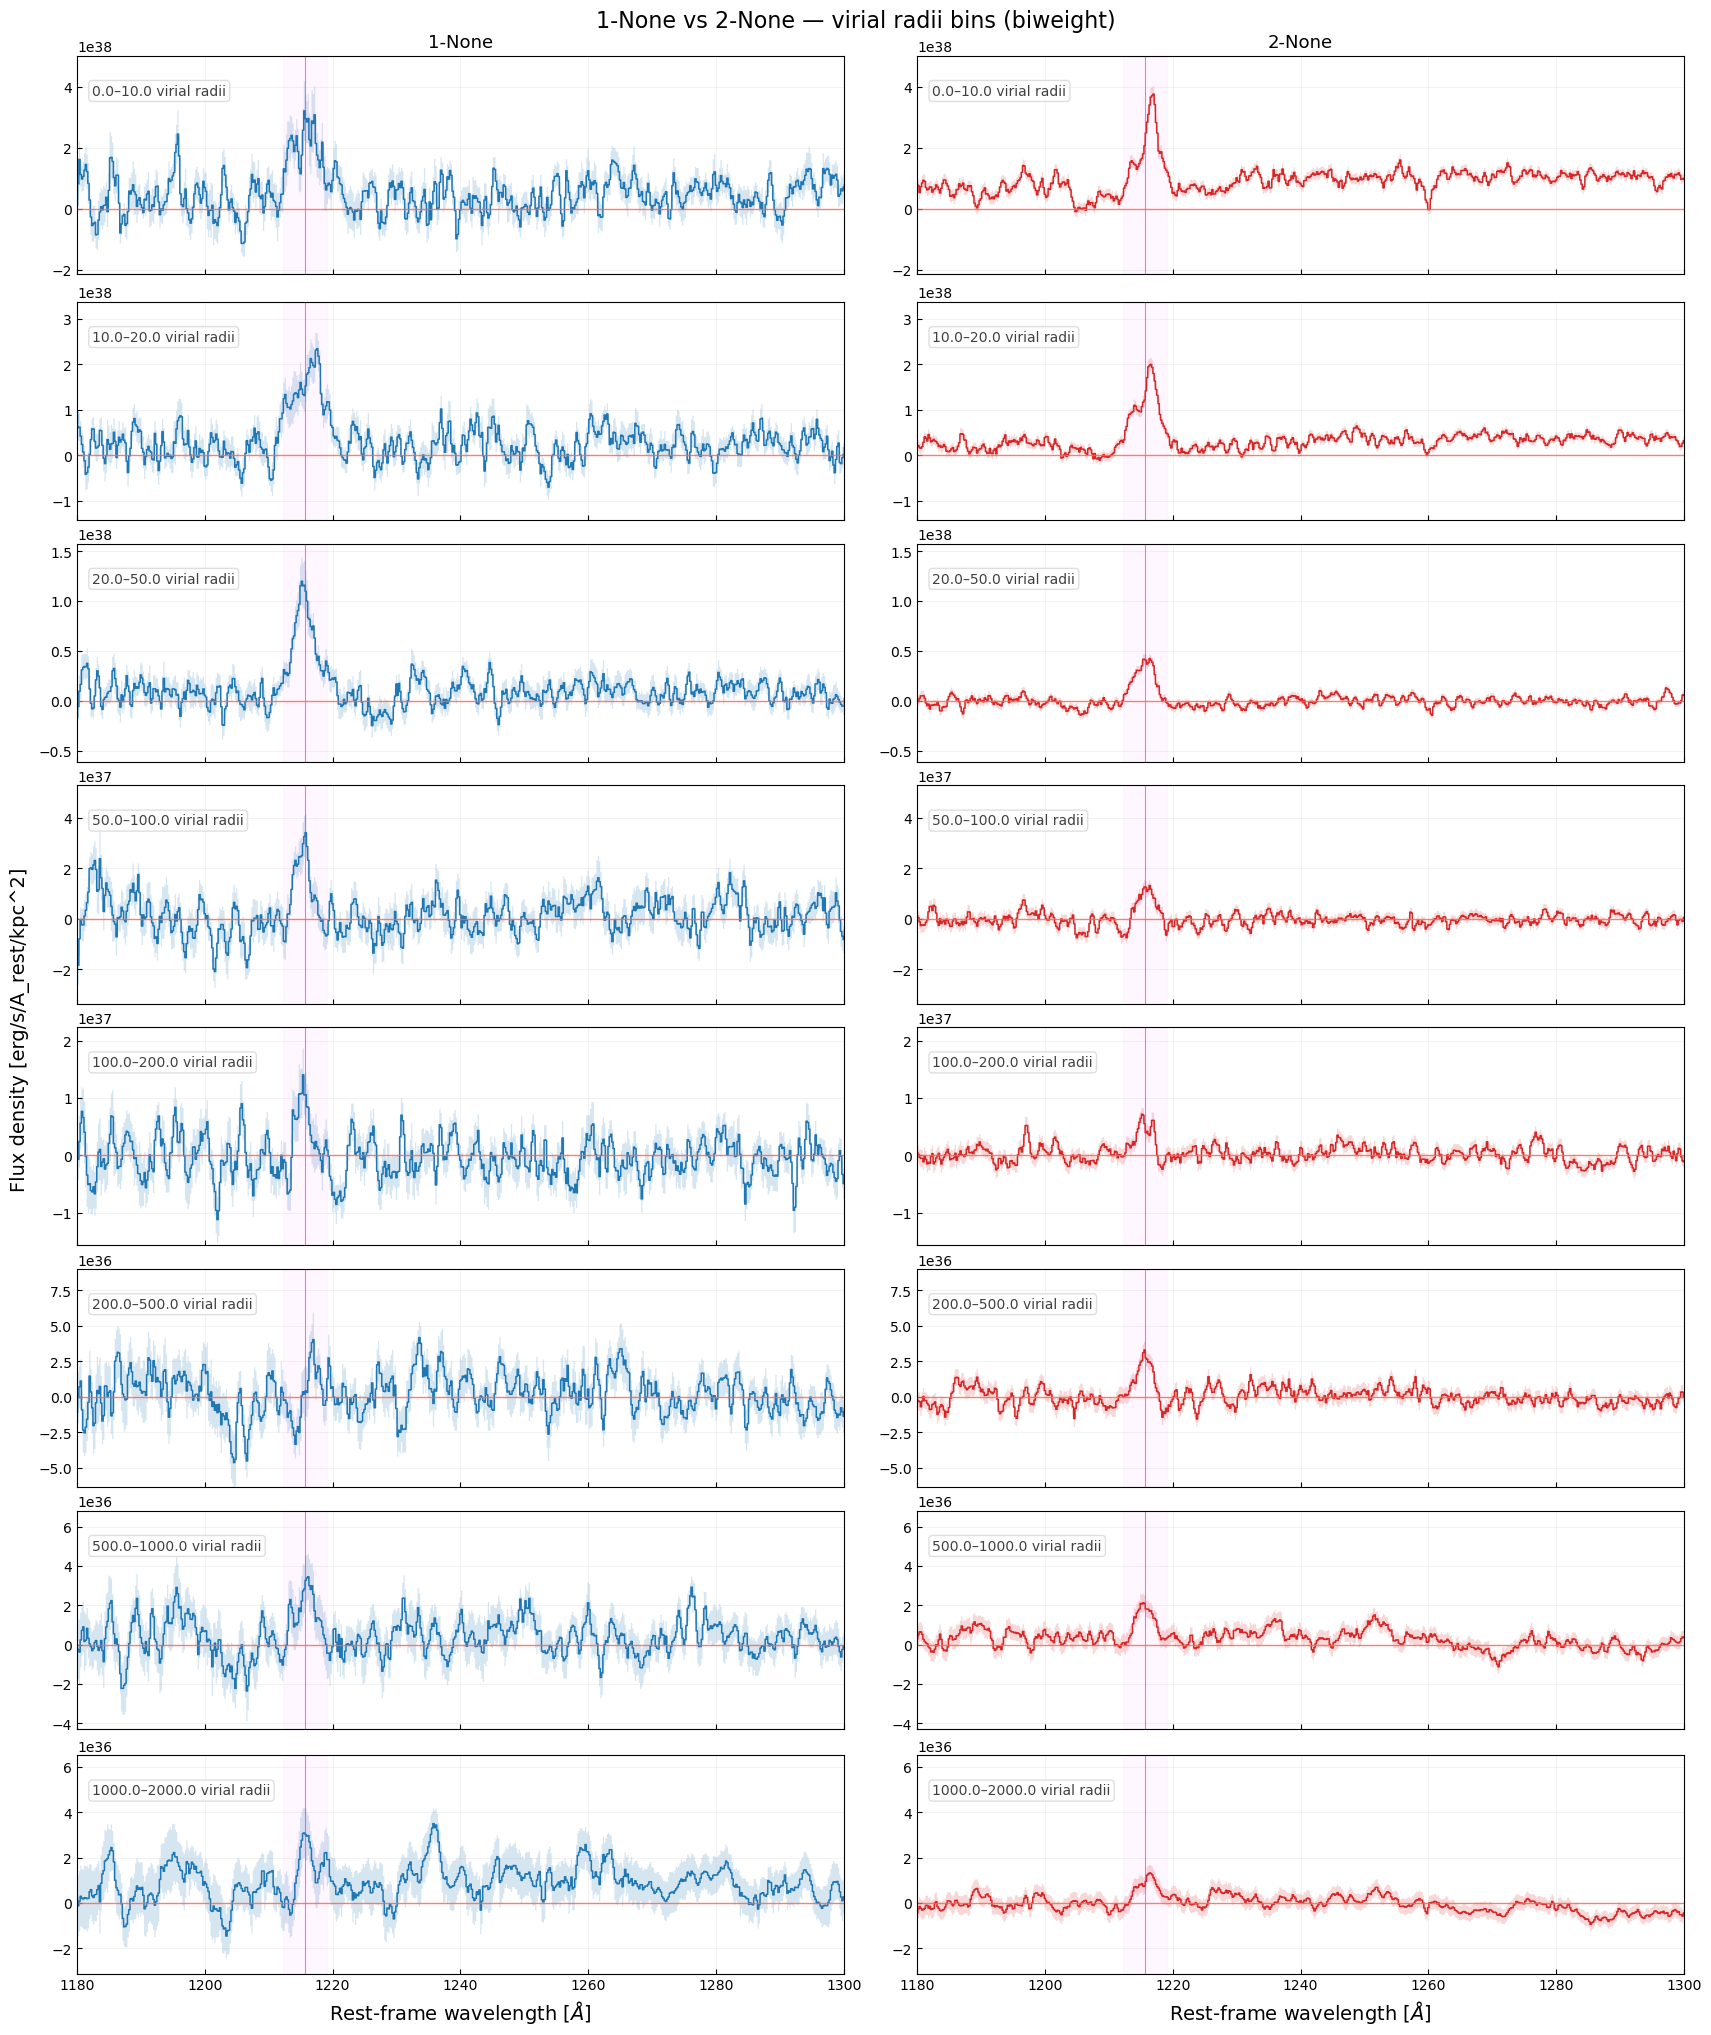

(<Figure size 1700x2000 with 16 Axes>,
 array([[<Axes: title={'center': '1-None'}>,
         <Axes: title={'center': '2-None'}>],
        [<Axes: >, <Axes: >],
        [<Axes: >, <Axes: >],
        [<Axes: >, <Axes: >],
        [<Axes: >, <Axes: >],
        [<Axes: >, <Axes: >],
        [<Axes: >, <Axes: >],
        [<Axes: xlabel='Rest-frame wavelength [$\\AA$]'>,
         <Axes: xlabel='Rest-frame wavelength [$\\AA$]'>]], dtype=object))

In [484]:
# all radial bins, both half-stacks on one figure
plotting.plot_stack_panels_two(stacks['low_sSFR'], stacks['high_sSFR'],
                               labels=(f"1-{None}", f"2-{None}"),
                               xlim=(1180, 1300),
                               lya_window=half_width)
plotting.plot_stack_panels_two(stacks['low_sSFR'], stacks['high_sSFR'],
                               labels=(f"1-{None}", f"2-{None}"),
                               layout="side",
                               xlim=(1180, 1300),
                               lya_window=half_width)

In [470]:
boot_both = multicat.measure_each(cfg, stacks)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

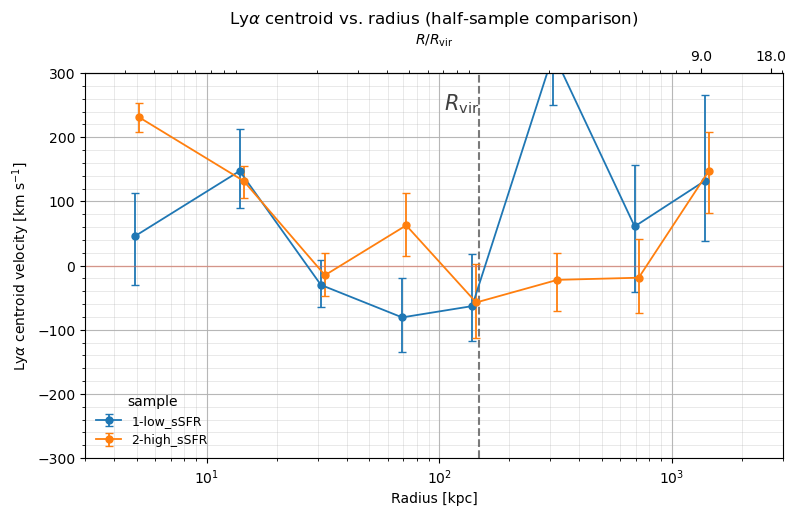

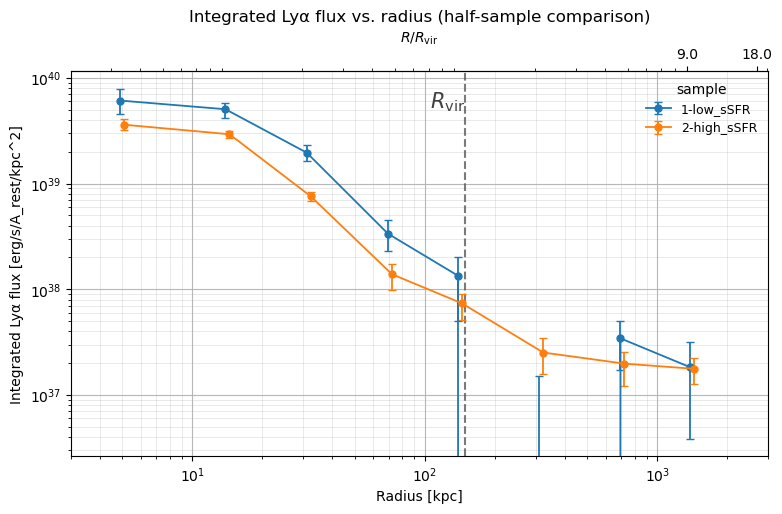

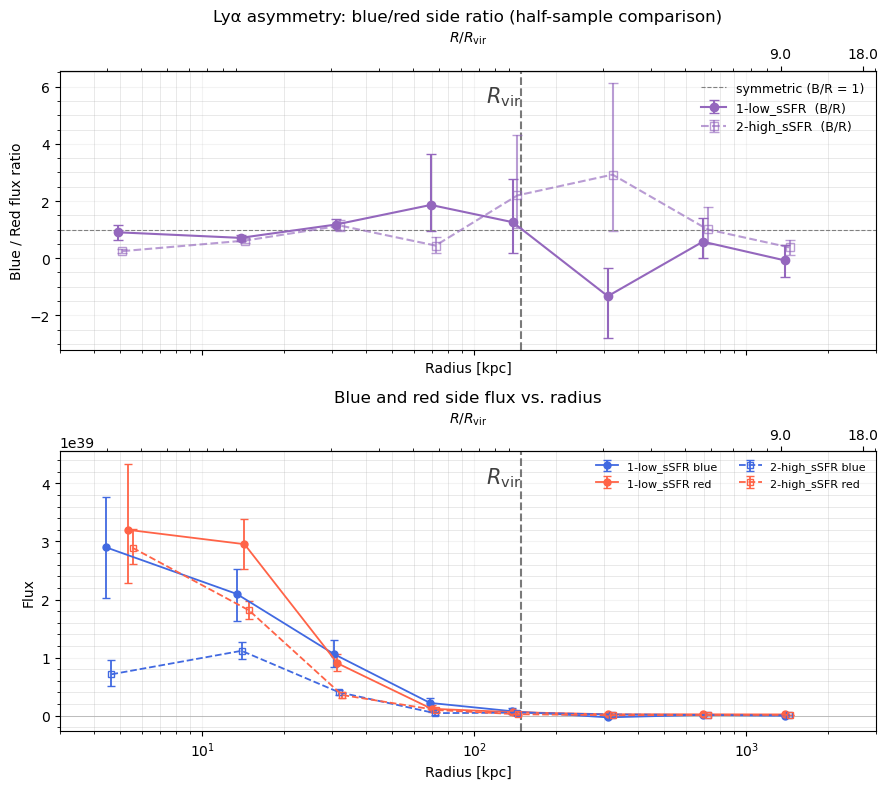

(<Figure size 900x800 with 2 Axes>,
 (<Axes: title={'center': 'Lyα asymmetry: blue/red side ratio (half-sample comparison)'}, xlabel='Radius [kpc]', ylabel='Blue / Red flux ratio'>,
  <Axes: title={'center': 'Blue and red side flux vs. radius'}, xlabel='Radius [kpc]', ylabel='Flux'>))

In [478]:
if (scale.lower() == 'kpc'):
    xlims = (3, 3000)
    vr_ticks = (vr_approx/10, vr_approx/5, vr_approx/2, vr_approx, vr_approx*2, vr_approx*5, vr_approx*10, vr_approx*20)
elif (scale.lower() == 'virial'):
    xlims = (0.03, 30)
else:
    print('NOOO')

# the three profiles, both samples per figure
analysis.plot_centroid_profile_two(boot_both['low_sSFR'], boot_both['high_sSFR'], stacks['low_sSFR'], stacks['high_sSFR'],
                                    labels=(f"1-low_sSFR", f"2-high_sSFR"),
                                    xlims=xlims,
                                    vr_ticks=vr_ticks,
                                    ylims=(-300, 300),
                                    bin_mode=scale,
                                    figsize=(9, 5))
analysis.plot_flux_profile_two(boot_both['low_sSFR'], boot_both['high_sSFR'], stacks['low_sSFR'], stacks['high_sSFR'],
                                    labels=(f"1-low_sSFR", f"2-high_sSFR"),
                                    xlims=xlims,
                                    vr_ticks=vr_ticks,
                                    bin_mode=scale,
                                    ylims=None,
                                    figsize=(9, 5))
analysis.plot_asymmetry_profile_two(boot_both['low_sSFR'], boot_both['high_sSFR'], stacks['low_sSFR'], stacks['high_sSFR'],
                                    labels=(f"1-low_sSFR", f"2-high_sSFR"),
                                    xlims=xlims,
                                    vr_ticks=vr_ticks,
                                    bin_mode=scale,
                                    figsize=(9, 8))